<a href="https://colab.research.google.com/github/keisahda-ship-it/hello-world/blob/main/GaitCSI_Colab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Setup

In [ ]:
import os, sys, subprocess
!nvidia-smi -L || echo "GPU tidak terdeteksi - training tetap jalan di CPU tapi lebih lambat"
!pip -q install PyWavelets gdown
REPO_DIR = "/content/GaitCSI-ID"
os.makedirs(f"{REPO_DIR}/src", exist_ok=True)
%cd {REPO_DIR}

GPU 0: Tesla T4 (UUID: GPU-74c2d51a-c970-a846-e20e-aeebc54e41d0)
/content/GaitCSI-ID


### 1.1 Preprocessing CSI — extraction, filtering, phase sanitization, feature structuring

In [ ]:
%%writefile src/preprocessing.py
"""
Preprocessing sinyal WiFi CSI untuk identifikasi orang berbasis gait.

Tahapan mengikuti panduan tugas:
  1. Extraction        : amplitudo dan fase dari matriks CSI kompleks
  2. Noise filtering   : Hampel (outlier), Butterworth low-pass, atau DWT denoising
  3. Phase sanitization: unwrapping + transformasi linier (hapus STO/SFO/CFO)
  4. Feature structuring: tensor (Channels, Subcarriers, Time) dan spektrogram STFT

Konvensi bentuk array: (antena, subcarrier, waktu) -> (A, K, T).
"""
from dataclasses import dataclass, asdict

import numpy as np
from scipy.signal import butter, sosfiltfilt, stft
from scipy.ndimage import median_filter


# ---------------------------------------------------------------------------
# 1. Extraction
# ---------------------------------------------------------------------------
def extract_amp_phase(csi):
    """Pisahkan CSI kompleks H = |H| e^{j angle(H)} menjadi amplitudo dan fase mentah."""
    csi = np.asarray(csi)
    if not np.iscomplexobj(csi):
        raise ValueError("extract_amp_phase membutuhkan CSI bernilai kompleks.")
    return np.abs(csi).astype(np.float32), np.angle(csi).astype(np.float32)


# ---------------------------------------------------------------------------
# 2. Noise filtering
# ---------------------------------------------------------------------------
def hampel_filter(x, window=7, n_sigma=3.0, axis=-1):
    """Ganti outlier impulsif (lonjakan akibat AGC/paket rusak) dengan median lokal.

    Implementasi tervektorisasi: median dan MAD dihitung dengan median_filter.
    """
    x = np.asarray(x, dtype=np.float32)
    size = [1] * x.ndim
    size[axis] = window
    med = median_filter(x, size=size, mode="nearest")
    mad = median_filter(np.abs(x - med), size=size, mode="nearest")
    thr = n_sigma * 1.4826 * mad
    out = x.copy()
    mask = np.abs(x - med) > thr
    out[mask] = med[mask]
    return out


def butter_lowpass(x, cutoff_hz, fs_hz, order=4, axis=-1):
    """Low-pass Butterworth zero-phase (filtfilt, bentuk SOS agar stabil numerik).

    Zero-phase penting: filter kausal menggeser fase temporal sehingga
    pola siklus langkah (gait cycle) akan terdistorsi.
    """
    nyq = 0.5 * fs_hz
    if not 0 < cutoff_hz < nyq:
        raise ValueError(f"cutoff {cutoff_hz} Hz harus di antara 0 dan Nyquist {nyq} Hz")
    sos = butter(order, cutoff_hz / nyq, btype="low", output="sos")
    return sosfiltfilt(sos, x, axis=axis).astype(np.float32)


def dwt_denoise(x, wavelet="db4", level=3, axis=-1):
    """Denoising wavelet dengan soft-threshold universal (VisuShrink, Donoho-Johnstone)."""
    import pywt

    x = np.asarray(x, dtype=np.float32)
    moved = np.moveaxis(x, axis, -1)
    flat = moved.reshape(-1, moved.shape[-1])
    out = np.empty_like(flat)
    n = flat.shape[-1]
    for i, sig in enumerate(flat):
        coeffs = pywt.wavedec(sig, wavelet, level=level)
        sigma = np.median(np.abs(coeffs[-1])) / 0.6745 + 1e-12
        thr = sigma * np.sqrt(2.0 * np.log(n))
        coeffs[1:] = [pywt.threshold(c, thr, mode="soft") for c in coeffs[1:]]
        out[i] = pywt.waverec(coeffs, wavelet)[:n]
    return np.moveaxis(out.reshape(moved.shape), -1, axis)


# ---------------------------------------------------------------------------
# 3. Phase sanitization
# ---------------------------------------------------------------------------
def sanitize_phase(phase, subcarrier_index=None, subcarrier_axis=-2):
    """Sanitasi fase linier (Sen et al., 2012; Qian et al., 2014).

    Fase terukur pada subcarrier k:  phi_hat_k = phi_k - 2*pi*(k/N)*delta_t + beta + Z
    Kesalahan delta_t (STO/SFO) bersifat linier terhadap indeks subcarrier dan
    beta (CFO) bersifat offset konstan. Setelah unwrapping sepanjang sumbu
    subcarrier, keduanya dihapus dengan:
        a = (phi_K - phi_1) / (k_K - k_1),   b = mean(phi)
        phi_sanitized = phi - a*k - b
    """
    phase = np.asarray(phase, dtype=np.float64)
    ph = np.unwrap(phase, axis=subcarrier_axis)
    ph = np.moveaxis(ph, subcarrier_axis, -1)
    K = ph.shape[-1]
    k = np.arange(K, dtype=np.float64) if subcarrier_index is None else np.asarray(subcarrier_index, np.float64)
    a = (ph[..., -1] - ph[..., 0]) / (k[-1] - k[0])
    detrended = ph - a[..., None] * k
    # b = mean(phi) pada formulasi asli mengasumsikan indeks subcarrier simetris
    # (sum k = 0); untuk indeks sembarang offset dihitung setelah detrending.
    b = detrended.mean(axis=-1)
    clean = detrended - b[..., None]
    return np.moveaxis(clean, -1, subcarrier_axis).astype(np.float32)


# ---------------------------------------------------------------------------
# 4. Feature structuring
# ---------------------------------------------------------------------------
def to_tensor_layout(x, n_antennas=3, n_subcarriers=114):
    """Ubah matriks NTU-Fi (A*K, T) menjadi (A, K, T)."""
    x = np.asarray(x, dtype=np.float32)
    if x.ndim == 2:
        x = x.reshape(n_antennas, n_subcarriers, x.shape[-1])
    return x


def doppler_spectrogram(x, fs_hz, nperseg=128, noverlap=96, n_components=1):
    """Spektrogram STFT dari komponen utama (PCA) lintas subcarrier per antena.

    PCA lintas subcarrier memusatkan energi gerak tubuh pada komponen pertama
    (pendekatan CARM, Wang et al. 2015) sehingga spektrogram merepresentasikan
    profil Doppler siklus langkah. Output: (A*n_components, F, T').
    """
    x = np.asarray(x, dtype=np.float32)
    A, K, T = x.shape
    specs = []
    for a in range(A):
        m = x[a] - x[a].mean(axis=1, keepdims=True)          # hilangkan komponen statis
        u, s, vt = np.linalg.svd(m.T, full_matrices=False)   # (T,K) -> PCA temporal
        for c in range(n_components):
            pc = u[:, c] * s[c]
            f, t, Z = stft(pc, fs=fs_hz, nperseg=nperseg, noverlap=noverlap)
            specs.append(np.log1p(np.abs(Z)))
    return f, t, np.stack(specs).astype(np.float32)


# ---------------------------------------------------------------------------
# Pipeline terkonfigurasi
# ---------------------------------------------------------------------------
@dataclass
class PreprocessConfig:
    fs_hz: float = 1000.0          # laju sampling CSI asli NTU-Fi (~1 kHz)
    hampel: bool = True
    denoise: str = "butter"        # "butter" | "dwt" | "none"
    cutoff_hz: float = 80.0        # pita Doppler gait pada 5 GHz <= ~80 Hz
    order: int = 4
    downsample: int = 4            # 2000 -> 500 sampel (setelah low-pass = anti-aliasing)
    log_amp: bool = False

    def to_dict(self):
        return asdict(self)


def preprocess_amplitude(x, cfg: PreprocessConfig):
    """Pipeline amplitudo: layout -> Hampel -> denoise -> downsample.

    Low-pass diterapkan SEBELUM decimation sehingga sekaligus berfungsi sebagai
    filter anti-aliasing (frekuensi Nyquist baru = fs/(2*downsample)).
    """
    x = to_tensor_layout(x)
    if cfg.log_amp:
        x = np.log1p(np.maximum(x, 0))
    if cfg.hampel:
        x = hampel_filter(x, axis=-1)
    if cfg.denoise == "butter":
        x = butter_lowpass(x, cfg.cutoff_hz, cfg.fs_hz, cfg.order, axis=-1)
    elif cfg.denoise == "dwt":
        x = dwt_denoise(x, axis=-1)
    if cfg.downsample > 1:
        x = x[..., :: cfg.downsample]
    return np.ascontiguousarray(x, dtype=np.float32)


def preprocess_complex(csi, cfg: PreprocessConfig):
    """Pipeline lengkap untuk CSI kompleks (bila dataset menyediakan fase).

    Mengembalikan tensor (2A, K, T'): A kanal amplitudo + A kanal fase tersanitasi.
    """
    amp, ph = extract_amp_phase(csi)
    amp = preprocess_amplitude(amp, cfg)
    ph = sanitize_phase(ph, subcarrier_axis=-2)
    if cfg.denoise != "none":
        ph = butter_lowpass(ph, cfg.cutoff_hz, cfg.fs_hz, cfg.order, axis=-1)
    ph = ph[..., :: cfg.downsample]
    return np.concatenate([amp, ph], axis=0)

Writing src/preprocessing.py


### 1.2 Data loader, normalisasi, split, dan PK-sampler untuk triplet

In [ ]:
%%writefile src/data.py
"""
Loader dataset NTU-Fi HumanID (SenseFi benchmark) + data sintetis untuk smoke test.

Struktur folder yang diharapkan (sesuai rilis SenseFi):
    NTU-Fi-HumanID/
        train_amp/<id subjek>/*.mat   (key 'CSIamp', bentuk 342 x 2000)
        test_amp/<id subjek>/*.mat
342 = 3 antena x 114 subcarrier, 2000 = sampel waktu.
"""
import glob
import os
import random

import numpy as np
import torch
from torch.utils.data import Dataset, Sampler

from .preprocessing import PreprocessConfig, preprocess_amplitude


# ---------------------------------------------------------------------------
# Membaca file
# ---------------------------------------------------------------------------
def load_mat(path, key="CSIamp"):
    """Baca .mat versi lama (scipy) maupun v7.3/HDF5 (h5py).

    Bila key 'CSIamp' tidak ada (salinan dataset tidak resmi), dipakai array
    numerik terbesar di dalam file.
    """
    try:
        import scipy.io as sio
        d = sio.loadmat(path)
        if key not in d:
            key = max((k for k in d if not k.startswith("__")), key=lambda k: np.size(d[k]))
        x = np.asarray(d[key], dtype=np.float32)
    except NotImplementedError:
        import h5py
        with h5py.File(path, "r") as f:
            if key not in f:
                key = max(f.keys(), key=lambda k: np.size(f[k]))
            x = np.asarray(f[key], dtype=np.float32).T
    if x.shape[0] != 342 and x.shape[-1] == 342:     # orientasi (T, 342)
        x = x.T
    return x


def list_split(root, split):
    """Kembalikan daftar (path, nama_kelas) terurut deterministik.

    Catatan: implementasi SenseFi memakai urutan glob tanpa sort sehingga
    pemetaan label bisa berbeda antar mesin; di sini diurutkan agar reproducible.
    """
    files = sorted(glob.glob(os.path.join(root, split, "*", "*.mat")))
    if not files:
        raise FileNotFoundError(f"Tidak ada file .mat di {os.path.join(root, split)}")
    return [(f, os.path.basename(os.path.dirname(f))) for f in files]


def find_dataset_root(search_dirs, name="NTU-Fi-HumanID", max_depth=4):
    """Cari folder dataset (berisi train_amp & test_amp) di beberapa lokasi."""
    for base in search_dirs:
        if not os.path.isdir(base):
            continue
        base_depth = base.rstrip(os.sep).count(os.sep)
        for dirpath, dirnames, _ in os.walk(base):
            if dirpath.count(os.sep) - base_depth >= max_depth:
                dirnames[:] = []
                continue
            if {"train_amp", "test_amp"} <= set(dirnames):
                return dirpath
    return None


def _has_class_mats(d):
    return bool(glob.glob(os.path.join(d, "*", "*.mat")))


def resolve_dataset(search_dirs, link_dir="/content/data/NTU-Fi-HumanID", max_depth=6):
    """Temukan dataset apa pun nama foldernya, lalu kembalikan root berlayout standar.

    Menerima layout resmi (train_amp/test_amp) maupun varian salinan seperti
    train/test atau Train/Test. Untuk varian, dibuat symlink train_amp & test_amp
    di link_dir sehingga kode lain cukup mengenal satu layout.
    """
    root = find_dataset_root(search_dirs, max_depth=max_depth)
    if root:
        return root
    for base in search_dirs:
        if not os.path.isdir(base):
            continue
        base_depth = base.rstrip(os.sep).count(os.sep)
        for dirpath, dirnames, _ in os.walk(base):
            if dirpath.count(os.sep) - base_depth >= max_depth:
                dirnames[:] = []
                continue
            tr = [d for d in dirnames if d.lower().startswith("train") and _has_class_mats(os.path.join(dirpath, d))]
            te = [d for d in dirnames if d.lower().startswith("test") and _has_class_mats(os.path.join(dirpath, d))]
            if tr and te:
                os.makedirs(link_dir, exist_ok=True)
                for src, dst in ((tr[0], "train_amp"), (te[0], "test_amp")):
                    p = os.path.join(link_dir, dst)
                    if not os.path.exists(p):
                        os.symlink(os.path.join(dirpath, src), p)
                return link_dir
    return None


def build_arrays(root, cfg: PreprocessConfig, cache_path=None, verbose=True):
    """Muat + preprocess seluruh split, simpan cache .npz agar run berikutnya instan."""
    if cache_path and os.path.exists(cache_path):
        d = np.load(cache_path, allow_pickle=True)
        if verbose:
            print(f"[cache] memuat {cache_path}")
        return {k: d[k] for k in d.files}

    out = {}
    train_items = list_split(root, "train_amp")
    classes = sorted({c for _, c in train_items})
    cmap = {c: i for i, c in enumerate(classes)}
    for split in ("train_amp", "test_amp"):
        items = list_split(root, split)
        X, y = [], []
        for i, (path, cls) in enumerate(items):
            X.append(preprocess_amplitude(load_mat(path), cfg))
            y.append(cmap[cls])
            if verbose and (i + 1) % 100 == 0:
                print(f"  {split}: {i + 1}/{len(items)}")
        tag = "train" if split.startswith("train") else "test"
        out[f"X{tag}"] = np.stack(X).astype(np.float32)
        out[f"y{tag}"] = np.asarray(y, dtype=np.int64)
    out["classes"] = np.asarray(classes)
    if cache_path:
        os.makedirs(os.path.dirname(cache_path) or ".", exist_ok=True)
        np.savez(cache_path, **out)
    return out


# ---------------------------------------------------------------------------
# Data sintetis (HANYA untuk smoke test pipeline, bukan untuk dilaporkan)
# ---------------------------------------------------------------------------
def synthetic_gait_raw(n_subjects=14, n_train=12, n_test=6, T=2000, fs=1000.0, seed=0):
    """Bangkitkan amplitudo CSI mentah (342 x T) bergaya gait.

    Tiap subjek memiliki: frekuensi langkah (cadence), rasio harmonik,
    profil gain subcarrier (proksi postur/ukuran tubuh), dan kecepatan Doppler.
    Ditambah derau Gaussian dan lonjakan impulsif agar tahap filtering teruji.
    """
    rng = np.random.default_rng(seed)
    t = np.arange(T) / fs
    k = np.arange(114)
    subj = []
    for _ in range(n_subjects):
        subj.append(dict(
            cadence=rng.uniform(1.6, 2.4),
            harm=rng.uniform(0.2, 0.8, size=3),
            dop=rng.uniform(20, 60),
            gain=1 + 0.3 * np.sin(2 * np.pi * (k / 114) * rng.uniform(1, 3) + rng.uniform(0, 6.28)),
            ant=rng.uniform(0.7, 1.3, size=3),
        ))

    def sample(p):
        phase0 = rng.uniform(0, 2 * np.pi)
        cad = p["cadence"] * rng.uniform(0.95, 1.05)
        body = sum(h * np.sin(2 * np.pi * (i + 1) * cad * t + phase0 * (i + 1)) for i, h in enumerate(p["harm"]))
        dopp = 0.3 * np.sin(2 * np.pi * p["dop"] * t + phase0) * (1 + 0.5 * np.sin(2 * np.pi * cad * t))
        sig = []
        for a in range(3):
            base = 40 + 4 * p["gain"][:, None] * p["ant"][a]
            s = base * (1 + 0.05 * body[None, :]) + p["gain"][:, None] * dopp[None, :]
            s = s + rng.normal(0, 0.8, size=s.shape)
            spikes = rng.random(s.shape) < 0.002
            s[spikes] += rng.normal(0, 15, size=spikes.sum())
            sig.append(s)
        return np.concatenate(sig, axis=0).astype(np.float32)

    data = {}
    for tag, n in (("train", n_train), ("test", n_test)):
        X, y = [], []
        for sid, p in enumerate(subj):
            for _ in range(n):
                X.append(sample(p))
                y.append(sid)
        data[f"raw{tag}"] = np.stack(X)
        data[f"y{tag}"] = np.asarray(y, dtype=np.int64)
    data["classes"] = np.asarray([f"S{i + 1:02d}" for i in range(n_subjects)])
    return data


def build_synthetic_arrays(cfg: PreprocessConfig, **kw):
    raw = synthetic_gait_raw(fs=cfg.fs_hz, **kw)
    return {
        "Xtrain": np.stack([preprocess_amplitude(x, cfg) for x in raw["rawtrain"]]),
        "ytrain": raw["ytrain"],
        "Xtest": np.stack([preprocess_amplitude(x, cfg) for x in raw["rawtest"]]),
        "ytest": raw["ytest"],
        "classes": raw["classes"],
    }


# ---------------------------------------------------------------------------
# Normalisasi, split, Dataset PyTorch
# ---------------------------------------------------------------------------
def fit_normalizer(X):
    """Statistik per antena dari data latih saja (mencegah kebocoran informasi uji)."""
    mean = X.mean(axis=(0, 2, 3), keepdims=True)[0]
    std = X.std(axis=(0, 2, 3), keepdims=True)[0] + 1e-6
    return mean.astype(np.float32), std.astype(np.float32)


def stratified_val_split(y, val_ratio=0.15, seed=42):
    from sklearn.model_selection import train_test_split
    idx = np.arange(len(y))
    tr, va = train_test_split(idx, test_size=val_ratio, stratify=y, random_state=seed)
    return np.sort(tr), np.sort(va)


def open_set_split(n_classes, n_unseen=4, seed=42):
    """Pilih subjek yang TIDAK pernah dilihat saat training (skenario open-set)."""
    rng = np.random.default_rng(seed)
    unseen = np.sort(rng.choice(n_classes, size=n_unseen, replace=False))
    seen = np.setdiff1d(np.arange(n_classes), unseen)
    return seen, unseen


class CSIDataset(Dataset):
    def __init__(self, X, y, mean, std, augment=False):
        self.X, self.y = X, y
        self.mean, self.std = mean, std
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def _augment(self, x):
        # 1) skala amplitudo per antena (variasi gain penerima)
        x = x * np.random.uniform(0.9, 1.1, size=(x.shape[0], 1, 1)).astype(np.float32)
        # 2) derau Gaussian kecil
        x = x + np.random.normal(0, 0.05, size=x.shape).astype(np.float32)
        # 3) time masking (SpecAugment-style) agar tidak bergantung pada segmen tunggal
        T = x.shape[-1]
        w = np.random.randint(0, max(1, T // 10))
        s = np.random.randint(0, T - w + 1)
        x[..., s:s + w] = 0.0
        return x

    def __getitem__(self, i):
        x = (self.X[i] - self.mean) / self.std
        if self.augment:
            x = self._augment(x.copy())
        return torch.from_numpy(np.ascontiguousarray(x, dtype=np.float32)), int(self.y[i])


class PKSampler(Sampler):
    """Batch berisi P identitas x K sampel; syarat agar batch-hard triplet bermakna."""

    def __init__(self, labels, p=7, k=4, seed=0):
        self.labels = np.asarray(labels)
        self.p, self.k = p, k
        self.by_class = {c: np.where(self.labels == c)[0].tolist() for c in np.unique(self.labels)}
        self.p = min(self.p, len(self.by_class))
        self.n_batches = max(1, len(self.labels) // (self.p * self.k))
        self.rng = random.Random(seed)

    def __len__(self):
        return self.n_batches

    def __iter__(self):
        classes = list(self.by_class)
        for _ in range(self.n_batches):
            batch = []
            for c in self.rng.sample(classes, self.p):
                pool = self.by_class[c]
                pick = self.rng.sample(pool, self.k) if len(pool) >= self.k else self.rng.choices(pool, k=self.k)
                batch.extend(pick)
            yield batch

Writing src/data.py


### 1.3 Arsitektur: baseline CNN1D dan usulan CNN-BiLSTM-Attention

In [ ]:
%%writefile src/models.py
"""
Arsitektur deep learning untuk identifikasi gait dari CSI.

Input semua model: tensor (B, A=3, K=114, T).
Output semua model: (logits, embedding). Embedding dipakai oleh triplet loss
dan untuk verifikasi biometrik (perbandingan cosine similarity).
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


class CNN1D(nn.Module):
    """Baseline: Conv1D temporal yang memperlakukan 342 deret (antena x subcarrier) sebagai kanal.

    Asumsi induktif: korelasi antar-subcarrier dipelajari secara penuh di layer
    pertama, tetapi dinamika temporal jarak jauh hanya ditangkap lewat
    receptive field konvolusi + global average pooling (orderless).
    """

    def __init__(self, n_classes, in_ch=342, emb_dim=128, dropout=0.3):
        super().__init__()

        def block(ci, co, k, pool=True):
            layers = [nn.Conv1d(ci, co, k, padding=k // 2), nn.BatchNorm1d(co), nn.ReLU(inplace=True)]
            if pool:
                layers.append(nn.MaxPool1d(2))
            return layers

        self.features = nn.Sequential(
            *block(in_ch, 128, 7), *block(128, 128, 5), *block(128, 256, 3, pool=False)
        )
        self.embed = nn.Sequential(nn.Dropout(dropout), nn.Linear(256, emb_dim))
        self.classifier = nn.Linear(emb_dim, n_classes)

    def forward(self, x):
        b, a, k, t = x.shape
        h = self.features(x.reshape(b, a * k, t))
        emb = self.embed(h.mean(dim=-1))
        return self.classifier(emb), emb


class TemporalAttention(nn.Module):
    """Additive attention pooling (Bahdanau-style) atas langkah waktu."""

    def __init__(self, dim, hidden=128):
        super().__init__()
        self.proj = nn.Linear(dim, hidden)
        self.score = nn.Linear(hidden, 1, bias=False)

    def forward(self, h):                       # h: (B, T, D)
        w = self.score(torch.tanh(self.proj(h))).squeeze(-1)
        w = torch.softmax(w, dim=1)
        return (h * w.unsqueeze(-1)).sum(1), w


class CNNBiLSTM(nn.Module):
    """Model usulan: front-end Conv2D (subcarrier x waktu) + BiLSTM + attention pooling.

    - Conv2D mengekstraksi pola lokal frekuensi-waktu (respons multipath tubuh
      pada subcarrier yang berdekatan) sambil mereduksi panjang sekuens 4x.
    - BiLSTM memodelkan dinamika siklus langkah (heel-strike -> swing) secara
      berurutan dua arah.
    - Attention pooling menimbang fase gait yang paling diskriminatif, alih-alih
      merata-ratakan seluruh jendela waktu.
    """

    def __init__(self, n_classes, in_ch=3, n_sub=114, emb_dim=128, hidden=128,
                 lstm_layers=2, dropout=0.3, attention=True):
        super().__init__()
        self.frontend = nn.Sequential(
            nn.Conv2d(in_ch, 16, (5, 7), stride=(2, 2), padding=(2, 3)), nn.BatchNorm2d(16), nn.ReLU(inplace=True),
            nn.Conv2d(16, 32, (5, 5), stride=(2, 2), padding=(2, 2)), nn.BatchNorm2d(32), nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, (3, 3), stride=(2, 1), padding=(1, 1)), nn.BatchNorm2d(64), nn.ReLU(inplace=True),
        )
        with torch.no_grad():
            f = self.frontend(torch.zeros(1, in_ch, n_sub, 64))
        feat_dim = f.shape[1] * f.shape[2]
        self.proj = nn.Sequential(nn.Linear(feat_dim, hidden), nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.lstm = nn.LSTM(hidden, hidden, num_layers=lstm_layers, batch_first=True,
                            bidirectional=True, dropout=dropout if lstm_layers > 1 else 0.0)
        self.use_attention = attention
        self.attn = TemporalAttention(2 * hidden) if attention else None
        self.embed = nn.Sequential(nn.Dropout(dropout), nn.Linear(2 * hidden, emb_dim))
        self.classifier = nn.Linear(emb_dim, n_classes)
        self.last_attn = None

    def forward(self, x):
        h = self.frontend(x)                              # (B, C, K', T')
        b, c, k, t = h.shape
        h = h.permute(0, 3, 1, 2).reshape(b, t, c * k)    # (B, T', C*K')
        h, _ = self.lstm(self.proj(h))                    # (B, T', 2H)
        if self.use_attention:
            pooled, w = self.attn(h)
            self.last_attn = w.detach()
        else:
            pooled = h.mean(dim=1)
        emb = self.embed(pooled)
        return self.classifier(emb), emb


def build_model(name, n_classes, **kw):
    name = name.lower()
    if name == "cnn1d":
        return CNN1D(n_classes, **kw)
    if name == "cnnbilstm":
        return CNNBiLSTM(n_classes, attention=True, **kw)
    if name == "cnnbilstm-noattn":
        return CNNBiLSTM(n_classes, attention=False, **kw)
    raise ValueError(f"Model tidak dikenal: {name}")


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

Writing src/models.py


### 1.4 Loss: Cross-Entropy + Batch-Hard Triplet

In [ ]:
%%writefile src/losses.py
"""
Fungsi loss: cross-entropy (klasifikasi closed-set) + batch-hard triplet (metric learning).

Batch-hard triplet (Hermans, Beyer & Leibe, 2017): untuk setiap anchor dipilih
positif TERJAUH dan negatif TERDEKAT di dalam batch, sehingga gradien terfokus
pada pasangan yang benar-benar sulit dibedakan (mis. dua orang dengan cadence mirip).
"""
import torch
import torch.nn as nn
import torch.nn.functional as F


class BatchHardTripletLoss(nn.Module):
    def __init__(self, margin=0.3):
        super().__init__()
        self.margin = margin

    def forward(self, emb, labels):
        emb = F.normalize(emb, dim=1)
        dist = torch.cdist(emb, emb, p=2)
        same = labels.unsqueeze(0) == labels.unsqueeze(1)
        eye = torch.eye(len(labels), dtype=torch.bool, device=emb.device)
        pos_mask = same & ~eye
        if pos_mask.sum() == 0:                         # batch tanpa pasangan positif
            return emb.new_zeros(())
        hardest_pos = (dist * pos_mask).max(dim=1).values
        hardest_neg = dist.masked_fill(same, float("inf")).min(dim=1).values
        valid = pos_mask.any(dim=1) & torch.isfinite(hardest_neg)
        loss = F.relu(hardest_pos - hardest_neg + self.margin)[valid]
        return loss.mean() if loss.numel() else emb.new_zeros(())


class JointLoss(nn.Module):
    """L = CE(label smoothing) + lambda * Triplet. lambda = 0 -> CE murni."""

    def __init__(self, triplet_weight=0.0, margin=0.3, label_smoothing=0.1):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
        self.tri = BatchHardTripletLoss(margin)
        self.w = triplet_weight

    def forward(self, logits, emb, labels):
        ce = self.ce(logits, labels)
        tri = self.tri(emb, labels) if self.w > 0 else logits.new_zeros(())
        return ce + self.w * tri, {"ce": ce.item(), "triplet": tri.item()}

Writing src/losses.py


### 1.5 Training loop (AdamW, OneCycle, AMP, early stopping pada validation set)

In [ ]:
%%writefile src/engine.py
"""
Loop training & inferensi (PyTorch), dengan early stopping berbasis validation set.

Test set TIDAK pernah dipakai untuk memilih epoch/hiperparameter, sehingga
angka akurasi uji yang dilaporkan bebas dari bias seleksi model.
"""
import copy
import os
import random
import time

import numpy as np
import torch
from torch.utils.data import DataLoader

from .losses import JointLoss
from .data import PKSampler


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


DEFAULT_TRAIN_CFG = dict(
    epochs=60, lr=1e-3, weight_decay=1e-4, batch_size=32,
    triplet_weight=0.0, margin=0.3, label_smoothing=0.1,
    pk_sampler=False, p=7, k=4, patience=15, num_workers=2, seed=42,
)


def _loader(ds, cfg, train):
    if train and cfg["pk_sampler"]:
        return DataLoader(ds, batch_sampler=PKSampler(ds.y, cfg["p"], cfg["k"], cfg["seed"]),
                          num_workers=cfg["num_workers"], pin_memory=torch.cuda.is_available())
    return DataLoader(ds, batch_size=cfg["batch_size"], shuffle=train, drop_last=False,
                      num_workers=cfg["num_workers"], pin_memory=torch.cuda.is_available())


@torch.no_grad()
def _evaluate_loss(model, loader, crit, device):
    model.eval()
    tot, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits, emb = model(x)
        loss, _ = crit(logits, emb, y)
        tot += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return tot / n, correct / n


def train_model(model, train_ds, val_ds, cfg=None, ckpt_path=None, verbose=True):
    cfg = {**DEFAULT_TRAIN_CFG, **(cfg or {})}
    set_seed(cfg["seed"])
    device = get_device()
    model = model.to(device)

    tr_loader, va_loader = _loader(train_ds, cfg, True), _loader(val_ds, cfg, False)
    crit = JointLoss(cfg["triplet_weight"], cfg["margin"], cfg["label_smoothing"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["lr"], epochs=cfg["epochs"],
                                                steps_per_epoch=len(tr_loader), pct_start=0.15)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    hist = {k: [] for k in ("train_loss", "train_acc", "val_loss", "val_acc", "ce", "triplet", "lr")}
    best = dict(val_acc=-1, val_loss=np.inf, epoch=-1, state=None)
    wait, t0 = 0, time.time()

    for ep in range(1, cfg["epochs"] + 1):
        model.train()
        tot, correct, n, ce_sum, tri_sum = 0.0, 0, 0, 0.0, 0.0
        for x, y in tr_loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                logits, emb = model(x)
                loss, parts = crit(logits.float(), emb.float(), y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt)
            scaler.update()
            sched.step()
            tot += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
            ce_sum += parts["ce"] * len(y)
            tri_sum += parts["triplet"] * len(y)

        va_loss, va_acc = _evaluate_loss(model, va_loader, crit, device)
        hist["train_loss"].append(tot / n); hist["train_acc"].append(correct / n)
        hist["val_loss"].append(va_loss); hist["val_acc"].append(va_acc)
        hist["ce"].append(ce_sum / n); hist["triplet"].append(tri_sum / n)
        hist["lr"].append(opt.param_groups[0]["lr"])

        improved = va_acc > best["val_acc"] or (va_acc == best["val_acc"] and va_loss < best["val_loss"])
        if improved:
            best.update(val_acc=va_acc, val_loss=va_loss, epoch=ep, state=copy.deepcopy(model.state_dict()))
            wait = 0
        else:
            wait += 1
        if verbose and (ep == 1 or ep % 5 == 0 or improved):
            print(f"ep {ep:3d} | train loss {tot / n:.4f} acc {correct / n:.3f} | "
                  f"val loss {va_loss:.4f} acc {va_acc:.3f}{'  *' if improved else ''}")
        if wait >= cfg["patience"]:
            if verbose:
                print(f"Early stopping pada epoch {ep} (terbaik: epoch {best['epoch']})")
            break

    model.load_state_dict(best["state"])
    info = dict(best_epoch=best["epoch"], best_val_acc=best["val_acc"],
                train_time_s=time.time() - t0, epochs_run=len(hist["val_acc"]))
    if ckpt_path:
        os.makedirs(os.path.dirname(ckpt_path) or ".", exist_ok=True)
        torch.save({"state_dict": best["state"], "cfg": cfg, "info": info}, ckpt_path)
    return model, hist, info


@torch.no_grad()
def predict(model, ds, batch_size=64):
    device = get_device()
    model = model.to(device).eval()
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False)
    ys, preds, probs, embs = [], [], [], []
    for x, y in loader:
        logits, emb = model(x.to(device))
        probs.append(torch.softmax(logits, 1).cpu())
        preds.append(logits.argmax(1).cpu())
        embs.append(emb.cpu())
        ys.append(y)
    # latensi inferensi satu sampel (rata-rata 20 kali, setelah warm-up)
    x1 = ds[0][0].unsqueeze(0).to(device)
    for _ in range(3):
        model(x1)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(20):
        model(x1)
    if device.type == "cuda":
        torch.cuda.synchronize()
    latency_ms = (time.perf_counter() - t0) / 20 * 1000
    return dict(y=torch.cat(ys).numpy(), pred=torch.cat(preds).numpy(),
                prob=torch.cat(probs).numpy(), emb=torch.cat(embs).numpy(), latency_ms=latency_ms)

Writing src/engine.py


### 1.6 Evaluasi & visualisasi

In [ ]:
%%writefile src/evaluation.py
"""
Evaluasi: metrik klasifikasi closed-set, verifikasi biometrik (ROC/EER),
identifikasi few-shot pada subjek tak terlihat (open-set), dan visualisasi.

Semua gambar disimpan 300 dpi dengan lebar ~1 kolom IEEE (3.5 in) atau
2 kolom (7.16 in) agar langsung dapat dipakai di technical report.
"""
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix, roc_curve,
                             roc_auc_score, top_k_accuracy_score, classification_report)

plt.rcParams.update({"font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8,
                     "legend.fontsize": 7, "figure.dpi": 110, "savefig.dpi": 300,
                     "savefig.bbox": "tight", "axes.spines.top": False, "axes.spines.right": False})
PALETTE = ["#4C6A92", "#C0504D", "#9BBB59", "#8064A2", "#F79646", "#4BACC6"]


# ---------------------------------------------------------------------------
# Closed-set identification
# ---------------------------------------------------------------------------
def classification_metrics(y, pred, prob, classes):
    labels = np.arange(len(classes))
    k = min(3, len(classes) - 1)
    return dict(
        accuracy=accuracy_score(y, pred),
        macro_f1=f1_score(y, pred, average="macro"),
        top3=top_k_accuracy_score(y, prob, k=k, labels=labels),
        report=classification_report(y, pred, labels=labels, target_names=[str(c) for c in classes],
                                     output_dict=True, zero_division=0),
    )


# ---------------------------------------------------------------------------
# Verifikasi biometrik (1:1)
# ---------------------------------------------------------------------------
def _cosine(emb):
    e = emb / (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-12)
    return e @ e.T


def verification_scores(emb, y):
    """Semua pasangan (i<j): genuine bila identitas sama, impostor bila berbeda.

    EER = titik di mana False Accept Rate = False Reject Rate; metrik baku
    biometrik yang tidak bergantung pada pilihan ambang tunggal.
    """
    s = _cosine(emb)
    iu = np.triu_indices(len(y), k=1)
    scores = s[iu]
    genuine = (y[:, None] == y[None, :])[iu].astype(int)
    fpr, tpr, thr = roc_curve(genuine, scores)
    fnr = 1 - tpr
    i = np.nanargmin(np.abs(fnr - fpr))
    eer = float((fpr[i] + fnr[i]) / 2)
    return dict(fpr=fpr, tpr=tpr, auc=float(roc_auc_score(genuine, scores)), eer=eer,
                eer_threshold=float(thr[i]), n_genuine=int(genuine.sum()),
                n_impostor=int((1 - genuine).sum()))


def fewshot_identification(emb, y, k_shot=1, n_trials=100, seed=0):
    """Enrollment k sampel/subjek -> centroid; sisanya diklasifikasi via cosine terdekat."""
    rng = np.random.default_rng(seed)
    e = emb / (np.linalg.norm(emb, axis=1, keepdims=True) + 1e-12)
    classes = np.unique(y)
    min_count = min((y == c).sum() for c in classes)
    if k_shot >= min_count:          # tidak ada sampel tersisa sebagai probe
        return float("nan"), float("nan")
    accs = []
    for _ in range(n_trials):
        cents, probe_idx = [], []
        for c in classes:
            idx = rng.permutation(np.where(y == c)[0])
            cents.append(e[idx[:k_shot]].mean(0))
            probe_idx.extend(idx[k_shot:])
        cents = np.stack(cents)
        cents /= np.linalg.norm(cents, axis=1, keepdims=True) + 1e-12
        probe_idx = np.asarray(probe_idx, dtype=np.int64)
        pred = classes[(e[probe_idx] @ cents.T).argmax(1)]
        accs.append((pred == y[probe_idx]).mean())
    return float(np.mean(accs)), float(np.std(accs))


# ---------------------------------------------------------------------------
# Plot
# ---------------------------------------------------------------------------
def plot_history(histories, path=None):
    fig, ax = plt.subplots(1, 2, figsize=(7.16, 2.4))
    for i, (name, h) in enumerate(histories.items()):
        c = PALETTE[i % len(PALETTE)]
        ep = np.arange(1, len(h["train_loss"]) + 1)
        ax[0].plot(ep, h["train_loss"], color=c, lw=1.2, label=f"{name} (train)")
        ax[0].plot(ep, h["val_loss"], color=c, lw=1.2, ls="--", label=f"{name} (val)")
        ax[1].plot(ep, h["train_acc"], color=c, lw=1.2)
        ax[1].plot(ep, h["val_acc"], color=c, lw=1.2, ls="--")
    ax[0].set(xlabel="Epoch", ylabel="Loss", title="(a) Training & validation loss")
    ax[1].set(xlabel="Epoch", ylabel="Accuracy", title="(b) Training & validation accuracy", ylim=(0, 1.02))
    for a in ax:
        a.grid(alpha=0.25, lw=0.5)
    handles, labels = ax[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.12, 1, 1))
    fig.legend(handles, labels, loc="lower center", ncol=min(4, len(labels)), frameon=False)
    if path:
        fig.savefig(path)
    return fig


def plot_confusion(y, pred, classes, title="", path=None, normalize=True):
    cm = confusion_matrix(y, pred, labels=np.arange(len(classes)))
    if normalize:
        cm = cm.astype(float) / np.maximum(cm.sum(1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(3.5, 3.2))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1 if normalize else None)
    n = len(classes)
    ax.set_xticks(range(n)); ax.set_yticks(range(n))
    ax.set_xticklabels(classes, rotation=90, fontsize=6); ax.set_yticklabels(classes, fontsize=6)
    for i in range(n):
        for j in range(n):
            v = cm[i, j]
            if v > 0.005:
                ax.text(j, i, f"{v:.2f}" if normalize else int(v), ha="center", va="center",
                        fontsize=4.5, color="white" if v > 0.6 else "black")
    ax.set(xlabel="Predicted subject", ylabel="True subject", title=title)
    fig.colorbar(im, fraction=0.046, pad=0.04)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig


def plot_roc(results, path=None, title="Verification ROC"):
    fig, ax = plt.subplots(figsize=(3.5, 3.0))
    for i, (name, r) in enumerate(results.items()):
        ax.plot(r["fpr"], r["tpr"], color=PALETTE[i % len(PALETTE)], lw=1.3,
                label=f"{name} (AUC {r['auc']:.3f}, EER {100 * r['eer']:.1f}%)")
    ax.plot([0, 1], [0, 1], color="grey", lw=0.6, ls=":")
    ax.plot([0, 1], [1, 0], color="grey", lw=0.4, ls=":")
    ax.set(xlabel="False accept rate", ylabel="True accept rate", title=title, xlim=(0, 1), ylim=(0, 1.01))
    ax.legend(loc="lower right", frameon=False)
    ax.grid(alpha=0.25, lw=0.5)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig


def plot_tsne(emb_dict, y, classes, path=None, seed=0):
    from sklearn.manifold import TSNE
    n = len(emb_dict)
    fig, axes = plt.subplots(1, n, figsize=(3.5 * n if n > 1 else 3.5, 3.0))
    axes = np.atleast_1d(axes)
    cmap = matplotlib.colormaps.get_cmap("tab20")
    for ax, (name, emb) in zip(axes, emb_dict.items()):
        z = TSNE(n_components=2, perplexity=min(30, len(y) // 4), init="pca", random_state=seed).fit_transform(emb)
        for c in np.unique(y):
            m = y == c
            ax.scatter(z[m, 0], z[m, 1], s=6, color=cmap(int(c) % 20), label=str(classes[c]))
        ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
    axes[-1].legend(fontsize=5, markerscale=1.5, frameon=False, bbox_to_anchor=(1.0, 1.0), loc="upper left")
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig


def plot_preprocessing(raw, stages, fs_list, sub=30, ant=0, path=None):
    """Bandingkan satu subcarrier pada tiap tahap preprocessing (domain waktu)."""
    fig, axes = plt.subplots(len(stages) + 1, 1, figsize=(7.16, 1.2 * (len(stages) + 1)), sharex=False)
    t = np.arange(raw.shape[-1]) / fs_list[0]
    axes[0].plot(t, raw[ant, sub], lw=0.5, color="grey"); axes[0].set_title("Raw amplitude", loc="left")
    for i, ((name, x), fs) in enumerate(zip(stages.items(), fs_list[1:]), start=1):
        tt = np.arange(x.shape[-1]) / fs
        axes[i].plot(tt, x[ant, sub], lw=0.7, color=PALETTE[(i - 1) % len(PALETTE)])
        axes[i].set_title(name, loc="left")
    axes[-1].set_xlabel("Time (s)")
    for a in axes:
        a.grid(alpha=0.25, lw=0.5)
    fig.tight_layout()
    if path:
        fig.savefig(path)
    return fig

Writing src/evaluation.py


### 1.7 Orkestrasi eksperimen (perbandingan model, ablation, open-set)

In [ ]:
%%writefile src/experiments.py
"""
Orkestrasi eksperimen: perbandingan model, ablation study, dan evaluasi open-set.

Matriks eksperimen (closed-set, 14 subjek):
  E1  CNN1D            + CE              -> baseline
  E2  CNN-BiLSTM-Attn  + CE              -> kontribusi arsitektur
  E3  CNN-BiLSTM-Attn  + CE + Triplet    -> model usulan (kontribusi metric learning)
  E4  CNN-BiLSTM (mean pooling) + CE + Triplet        -> ablation attention
  E5  CNN-BiLSTM-Attn  + CE + Triplet, tanpa filtering -> ablation preprocessing
Open-set (subjek uji tidak pernah dilihat saat training):
  O1  CNN-BiLSTM-Attn + CE   vs   O2  CNN-BiLSTM-Attn + CE + Triplet
"""
import json
import os

import numpy as np
import pandas as pd

from .data import CSIDataset, fit_normalizer, stratified_val_split, open_set_split
from .engine import train_model, predict, set_seed
from .evaluation import classification_metrics, verification_scores, fewshot_identification
from .models import build_model, count_params

EXPERIMENTS = {
    "E1": dict(label="CNN1D (CE)", model="cnn1d", triplet=0.0, data="filtered"),
    "E2": dict(label="CNN-BiLSTM-Attn (CE)", model="cnnbilstm", triplet=0.0, data="filtered"),
    "E3": dict(label="CNN-BiLSTM-Attn (CE+Triplet)", model="cnnbilstm", triplet=1.0, data="filtered"),
    "E4": dict(label="w/o attention (CE+Triplet)", model="cnnbilstm-noattn", triplet=1.0, data="filtered"),
    "E5": dict(label="w/o filtering (CE+Triplet)", model="cnnbilstm", triplet=1.0, data="raw"),
}
OPENSET = {
    "O1": dict(label="CNN-BiLSTM-Attn (CE)", model="cnnbilstm", triplet=0.0, data="filtered"),
    "O2": dict(label="CNN-BiLSTM-Attn (CE+Triplet)", model="cnnbilstm", triplet=1.0, data="filtered"),
}


def _attach_metadata(ckpt_path, model_name, classes, norm, preprocess_cfg):
    """Simpan semua yang dibutuhkan inferensi mandiri (infer.py) ke dalam checkpoint."""
    import torch
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    ck.update(model_name=model_name, classes=[str(c) for c in classes],
              mean=norm[0], std=norm[1], preprocess=preprocess_cfg)
    torch.save(ck, ckpt_path)


def _datasets(arrays, train_idx, val_idx, test_mask=None):
    Xtr, ytr = arrays["Xtrain"], arrays["ytrain"]
    mean, std = fit_normalizer(Xtr[train_idx])
    tr = CSIDataset(Xtr[train_idx], ytr[train_idx], mean, std, augment=True)
    va = CSIDataset(Xtr[val_idx], ytr[val_idx], mean, std, augment=False)
    Xte, yte = arrays["Xtest"], arrays["ytest"]
    if test_mask is not None:
        Xte, yte = Xte[test_mask], yte[test_mask]
    te = CSIDataset(Xte, yte, mean, std, augment=False)
    return tr, va, te, (mean, std)


def run_closed_set(arrays_by_variant, exp_ids=None, seeds=(42,), train_cfg=None, outdir="results",
                   verbose=True):
    exp_ids = exp_ids or list(EXPERIMENTS)
    os.makedirs(os.path.join(outdir, "checkpoints"), exist_ok=True)
    rows, store = [], {}
    for eid in exp_ids:
        spec = EXPERIMENTS[eid]
        arrays = arrays_by_variant[spec["data"]]
        classes = arrays["classes"]
        for seed in seeds:
            set_seed(seed)
            tr_idx, va_idx = stratified_val_split(arrays["ytrain"], 0.15, seed)
            tr, va, te, norm = _datasets(arrays, tr_idx, va_idx)
            cfg = {**(train_cfg or {}), "seed": seed, "triplet_weight": spec["triplet"],
                   "pk_sampler": spec["triplet"] > 0}
            model = build_model(spec["model"], len(classes))
            if verbose:
                print(f"\n=== {eid} | {spec['label']} | seed {seed} | params {count_params(model):,} ===")
            ckpt = os.path.join(outdir, "checkpoints", f"{eid}-seed{seed}.pt")
            model, hist, info = train_model(model, tr, va, cfg, ckpt_path=ckpt, verbose=verbose)
            _attach_metadata(ckpt, spec["model"], classes, norm, arrays.get("preprocess"))
            out = predict(model, te)
            m = classification_metrics(out["y"], out["pred"], out["prob"], classes)
            v = verification_scores(out["emb"], out["y"])
            rows.append(dict(exp=eid, model=spec["label"], seed=seed, params=count_params(model),
                             test_acc=m["accuracy"], macro_f1=m["macro_f1"], top3=m["top3"],
                             ver_auc=v["auc"], ver_eer=v["eer"], best_epoch=info["best_epoch"],
                             val_acc=info["best_val_acc"], train_time_s=info["train_time_s"],
                             latency_ms=out["latency_ms"]))
            store[(eid, seed)] = dict(hist=hist, out=out, metrics=m, ver=v, norm=norm, model=model)
            if verbose:
                print(f"--> test acc {m['accuracy']:.4f} | macro-F1 {m['macro_f1']:.4f} | "
                      f"EER {100 * v['eer']:.2f}%")
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(outdir, "closedset-runs.csv"), index=False)
    return df, store


def run_open_set(arrays, n_unseen=4, seeds=(42,), train_cfg=None, outdir="results", k_shots=(1, 5),
                 verbose=True):
    """Latih pada subjek 'seen', uji verifikasi & few-shot pada subjek 'unseen'.

    Ini menguji klaim inti biometrik: apakah embedding menggeneralisasi ke
    identitas baru tanpa retraining (kebutuhan nyata saat pengguna baru mendaftar).
    """
    rows, store = [], {}
    n_classes = len(arrays["classes"])
    for seed in seeds:
        seen, unseen = open_set_split(n_classes, n_unseen, seed)
        remap = {c: i for i, c in enumerate(seen)}
        mtr = np.isin(arrays["ytrain"], seen)
        sub = dict(Xtrain=arrays["Xtrain"][mtr],
                   ytrain=np.asarray([remap[c] for c in arrays["ytrain"][mtr]]),
                   Xtest=arrays["Xtest"], ytest=arrays["ytest"], classes=arrays["classes"][seen])
        tr_idx, va_idx = stratified_val_split(sub["ytrain"], 0.15, seed)
        test_mask = np.isin(arrays["ytest"], unseen)
        for oid, spec in OPENSET.items():
            set_seed(seed)
            tr, va, te, _ = _datasets(sub, tr_idx, va_idx, test_mask)
            cfg = {**(train_cfg or {}), "seed": seed, "triplet_weight": spec["triplet"],
                   "pk_sampler": spec["triplet"] > 0}
            model = build_model(spec["model"], len(seen))
            if verbose:
                print(f"\n=== {oid} open-set | {spec['label']} | seed {seed} | unseen {arrays['classes'][unseen].tolist()} ===")
            model, hist, info = train_model(model, tr, va, cfg, verbose=verbose)
            out = predict(model, te)
            v = verification_scores(out["emb"], out["y"])
            row = dict(exp=oid, model=spec["label"], seed=seed, n_unseen=n_unseen,
                       unseen_auc=v["auc"], unseen_eer=v["eer"])
            for k in k_shots:
                mu, sd = fewshot_identification(out["emb"], out["y"], k_shot=k, seed=seed)
                row[f"{k}shot_acc"] = mu
                row[f"{k}shot_std"] = sd
            rows.append(row)
            store[(oid, seed)] = dict(ver=v, out=out, unseen=unseen)
            if verbose:
                print(f"--> unseen EER {100 * v['eer']:.2f}% | AUC {v['auc']:.4f} | "
                      + " | ".join(f"{k}-shot {row[f'{k}shot_acc']:.3f}" for k in k_shots))
    df = pd.DataFrame(rows)
    df.to_csv(os.path.join(outdir, "openset-runs.csv"), index=False)
    return df, store


def summarize(df, keys=("exp", "model"), metrics=None):
    """Rangkum mean +- std lintas seed menjadi tabel siap-laporan."""
    metrics = metrics or [c for c in df.columns if df[c].dtype.kind == "f" and c not in ("seed",)]
    g = df.groupby(list(keys), sort=False)[metrics]
    mean, std = g.mean(), g.std().fillna(0)
    out = mean.copy().astype(object)
    for c in metrics:
        out[c] = [f"{m:.4f} ± {s:.4f}" if s > 0 else f"{m:.4f}" for m, s in zip(mean[c], std[c])]
    return out.reset_index()


def save_json(obj, path):
    def conv(o):
        if isinstance(o, (np.floating, np.integer)):
            return o.item()
        if isinstance(o, np.ndarray):
            return o.tolist()
        return str(o)
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=conv)

Writing src/experiments.py


### 1.8 Ekspor hasil ke LaTeX (angka & interpretasi laporan dibuat otomatis)

In [ ]:
%%writefile src/reporting.py
"""
Ekspor hasil eksperimen ke LaTeX untuk technical report IEEE.

Menghasilkan (di folder report/):
  results.tex          macro angka (\\AccEthree, \\EerOtwo, ...) + kalimat interpretasi
                       yang arahnya ditentukan dari data (naik/turun/setara)
  table-closedset.tex  baris tabel perbandingan model & ablation
  table-openset.tex    baris tabel evaluasi open-set
  figures/             salinan grafik 300 dpi
Laporan (GaitCSI-Report.tex) cukup meng-\\input file-file ini, sehingga angka di
laporan selalu identik dengan hasil run terakhir.
"""
import os
import shutil

import numpy as np
from sklearn.metrics import confusion_matrix

WORD = {"E1": "Eone", "E2": "Etwo", "E3": "Ethree", "E4": "Efour", "E5": "Efive",
        "O1": "Oone", "O2": "Otwo"}


def _pm(mean, std, scale=100.0, nd=2):
    s = f"{scale * mean:.{nd}f}"
    if std and std > 0:
        s += f"\\,$\\pm$\\,{scale * std:.{nd}f}"
    return s


def _tex(s):
    return str(s).replace("_", "\\_").replace("&", "\\&").replace("%", "\\%")


def _verb(delta, tol, up="meningkatkan", down="menurunkan"):
    if abs(delta) < tol:
        return "hampir tidak mengubah"
    return up if delta > 0 else down


def _interp_arch(d, tol):
    if d > tol:
        return ("Hal ini mengindikasikan bahwa pemodelan sekuensial dua arah beserta pembobotan temporal "
                "menangkap struktur siklus langkah yang hilang ketika fitur temporal diringkas secara "
                "\\textit{orderless} melalui global average pooling.")
    if d < -tol:
        return ("Temuan ini menunjukkan bahwa pada jumlah sampel latih yang terbatas, kapasitas tambahan "
                "BiLSTM belum terkonversi menjadi generalisasi yang lebih baik; bias induktif konvolusi "
                "temporal yang lebih sederhana tampaknya sudah cukup untuk memisahkan 14 subjek.")
    return ("Kesetaraan ini menunjukkan bahwa pada skenario \\textit{closed-set}, informasi identitas sudah "
            "terkandung kuat dalam statistik spektral-temporal lokal sehingga urutan fase gait tidak "
            "memberikan keuntungan diskriminatif tambahan yang terukur.")


def _interp_triplet_closed(d, tol):
    if d > tol:
        return ("Batasan jarak dari triplet loss bertindak sebagai regularisasi geometris yang memadatkan "
                "klaster intra-subjek, sehingga keputusan klasifikasi menjadi lebih tegas.")
    if d < -tol:
        return ("Penurunan ini wajar karena triplet loss mengoptimalkan geometri embedding, bukan batas "
                "keputusan softmax secara langsung; selain itu PK-sampler menghasilkan lebih sedikit "
                "iterasi per epoch dibanding sampling acak.")
    return ("Pada skenario \\textit{closed-set}, sinyal supervisi dari cross-entropy tampaknya sudah "
            "memadai, sehingga manfaat triplet loss perlu dinilai pada skenario open-set.")


def _interp_open(d_eer, tol):
    # d_eer = EER(O2) - EER(O1); negatif berarti triplet lebih baik
    if d_eer < -tol:
        return ("Hasil ini merupakan bukti paling langsung atas kontribusi metric learning: embedding yang "
                "dilatih dengan triplet loss lebih mampu memisahkan identitas yang belum pernah dilihat, "
                "sebuah prasyarat bagi pendaftaran pengguna baru tanpa pelatihan ulang.")
    if d_eer > tol:
        return ("Hasil ini berlawanan dengan ekspektasi teoretis. Penjelasan yang paling mungkin adalah "
                "jumlah identitas latih yang hanya 10 subjek, sehingga variasi negatif sulit di dalam batch "
                "terlalu sempit untuk membentuk ruang embedding yang benar-benar umum.")
    return ("Kesetaraan ini mengindikasikan bahwa dengan hanya 10 identitas latih, cross-entropy dengan "
            "label smoothing sudah menghasilkan embedding yang cukup terstruktur untuk subjek baru.")


def _interp_removal(d, tol, component):
    # d = metrik(tanpa komponen) - metrik(lengkap); negatif berarti komponen membantu
    if d < -tol:
        return f"Dengan demikian, {component} terbukti memberikan kontribusi positif terhadap kinerja."
    if d > tol:
        return (f"Artinya, {component} tidak memberi kontribusi positif pada konfigurasi ini; temuan ini "
                "dilaporkan apa adanya dan dibahas pada bagian keterbatasan.")
    return f"Artinya, kontribusi {component} berada dalam batas variasi acak pelatihan."


def export_latex(runs, open_runs, store, arrays, report_dir, fig_dir, seeds, classes):
    os.makedirs(os.path.join(report_dir, "figures"), exist_ok=True)
    for f in os.listdir(fig_dir):
        if f.endswith(".png"):
            shutil.copy(os.path.join(fig_dir, f), os.path.join(report_dir, "figures", f))

    agg = runs.groupby("exp", sort=False).agg({c: ["mean", "std"] for c in runs.columns if runs[c].dtype.kind in "fi" and c != "seed"})
    get = lambda e, m: (agg.loc[e, (m, "mean")], agg.loc[e, (m, "std")] if len(seeds) > 1 else 0.0)
    L = ["% File ini dibuat otomatis oleh src/reporting.py -- jangan diedit manual."]
    mac = lambda n, v: L.append(f"\\newcommand{{\\{n}}}{{{v}}}")

    # ---- dataset
    mac("NSub", len(classes))
    mac("NTrain", len(arrays["ytrain"]))
    mac("NTest", len(arrays["ytest"]))
    mac("NSeeds", len(seeds))
    mac("SeedList", ", ".join(map(str, seeds)))
    mac("SeedNote", "rata-rata $\\pm$ simpangan baku dari " + f"{len(seeds)} seed" if len(seeds) > 1
        else f"satu seed ({seeds[0]})")

    # ---- closed-set
    rows = []
    for e in runs["exp"].unique():
        w = WORD[e]
        acc, f1, t3, eer, auc = (get(e, m) for m in ("test_acc", "macro_f1", "top3", "ver_eer", "ver_auc"))
        lat = agg.loc[e, ("latency_ms", "mean")]
        par = int(agg.loc[e, ("params", "mean")])
        mac(f"Acc{w}", _pm(*acc)); mac(f"Fone{w}", _pm(*f1)); mac(f"Eer{w}", _pm(*eer))
        mac(f"Auc{w}", _pm(*auc, scale=1, nd=4)); mac(f"Lat{w}", f"{lat:.1f}")
        mac(f"Params{w}", f"{par / 1e3:.0f}k")
        label = runs.loc[runs.exp == e, "model"].iloc[0]
        rows.append(f"{e} & {_tex(label)} & {par / 1e3:.0f}k & {_pm(*acc)} & {_pm(*f1)} & "
                    f"{_pm(*t3)} & {_pm(*eer)} & {lat:.1f} \\\\")
    with open(os.path.join(report_dir, "table-closedset.tex"), "w") as f:
        f.write("\n".join(rows) + "\n")

    m = lambda e, k="test_acc": agg.loc[e, (k, "mean")] if e in agg.index else np.nan
    tol = 0.005
    best = agg[("test_acc", "mean")].idxmax()
    mac("BestExp", best)
    mac("BestModel", _tex(runs.loc[runs.exp == best, "model"].iloc[0]))
    mac("BestAcc", f"{100 * m(best):.2f}")
    comps = {
        "Arch": ("E2", "E1", _interp_arch),
        "Tri": ("E3", "E2", _interp_triplet_closed),
    }
    for name, (a, b, fn) in comps.items():
        if a in agg.index and b in agg.index:
            d = m(a) - m(b)
            mac(f"D{name}", f"{100 * abs(d):.2f}")
            mac(f"V{name}", _verb(d, tol))
            mac(f"I{name}", fn(d, tol))
    for name, (a, comp) in {"Attn": ("E4", "temporal attention"), "Filt": ("E5", "tahap filtering")}.items():
        if a in agg.index and "E3" in agg.index:
            d = m(a) - m("E3")
            mac(f"D{name}", f"{100 * abs(d):.2f}")
            mac(f"V{name}", _verb(d, tol))
            mac(f"I{name}", _interp_removal(d, tol, comp))
            de = m(a, "ver_eer") - m("E3", "ver_eer")
            mac(f"VEer{name}", _verb(de, 0.002, "menaikkan", "menurunkan"))

    # ---- analisis kesalahan model usulan
    key = ("E3", seeds[0]) if ("E3", seeds[0]) in store else next(iter(store))
    o = store[key]["out"]
    cm = confusion_matrix(o["y"], o["pred"], labels=np.arange(len(classes)))
    recall = cm.diagonal() / np.maximum(cm.sum(1), 1)
    mac("NPerfect", int((recall >= 0.999).sum()))
    worst = int(recall.argmin())
    mac("WorstSubject", _tex(classes[worst])); mac("WorstRecall", f"{100 * recall[worst]:.1f}")
    off = cm.copy(); np.fill_diagonal(off, 0)
    i, j = np.unravel_index(off.argmax(), off.shape)
    mac("ConfTrue", _tex(classes[i])); mac("ConfPred", _tex(classes[j])); mac("ConfCount", int(off[i, j]))

    # ---- open-set
    if open_runs is not None and len(open_runs):
        oagg = open_runs.groupby("exp", sort=False).agg({c: ["mean", "std"] for c in open_runs.columns if open_runs[c].dtype.kind in "fi" and c != "seed"})
        g = lambda e, k: (oagg.loc[e, (k, "mean")], oagg.loc[e, (k, "std")] if len(seeds) > 1 else 0.0)
        orows = []
        for e in open_runs["exp"].unique():
            w = WORD[e]
            vals = {k: g(e, k) for k in ("unseen_auc", "unseen_eer", "1shot_acc", "5shot_acc")}
            mac(f"Eer{w}", _pm(*vals["unseen_eer"])); mac(f"Auc{w}", _pm(*vals["unseen_auc"], scale=1, nd=4))
            mac(f"OneShot{w}", _pm(*vals["1shot_acc"])); mac(f"FiveShot{w}", _pm(*vals["5shot_acc"]))
            label = open_runs.loc[open_runs.exp == e, "model"].iloc[0]
            orows.append(f"{e} & {_tex(label)} & {_pm(*vals['unseen_auc'], scale=1, nd=4)} & "
                         f"{_pm(*vals['unseen_eer'])} & {_pm(*vals['1shot_acc'])} & {_pm(*vals['5shot_acc'])} \\\\")
        with open(os.path.join(report_dir, "table-openset.tex"), "w") as f:
            f.write("\n".join(orows) + "\n")
        d_eer = oagg.loc["O2", ("unseen_eer", "mean")] - oagg.loc["O1", ("unseen_eer", "mean")]
        mac("DOpen", f"{100 * abs(d_eer):.2f}")
        mac("VOpen", _verb(d_eer, 0.002, "menaikkan", "menurunkan"))
        mac("IOpen", _interp_open(d_eer, 0.002))
        d1 = oagg.loc["O2", ("1shot_acc", "mean")] - oagg.loc["O1", ("1shot_acc", "mean")]
        mac("VOneShot", _verb(d1, tol))
        mac("DOneShot", f"{100 * abs(d1):.2f}")
        mac("NUnseen", int(open_runs["n_unseen"].iloc[0]))

    with open(os.path.join(report_dir, "results.tex"), "w") as f:
        f.write("\n".join(L) + "\n")
    return os.path.join(report_dir, "results.tex")

Writing src/reporting.py


### 1.9 CLI training & inferensi, requirements, naskah laporan IEEE

In [ ]:
%%writefile train.py
"""
CLI: jalankan seluruh eksperimen (closed-set + ablation + open-set) dan simpan
tabel serta grafik ke folder results/.

Contoh:
    python train.py --data-root data/NTU-Fi-HumanID
    python train.py --data-root data/NTU-Fi-HumanID --seeds 42 7 2026 --epochs 80
    python train.py --synthetic --epochs 5          # smoke test tanpa dataset
"""
import argparse
import os

import numpy as np

from src.preprocessing import PreprocessConfig
from src.data import build_arrays, build_synthetic_arrays
from src.experiments import run_closed_set, run_open_set, summarize, EXPERIMENTS
from src.evaluation import plot_history, plot_confusion, plot_roc, plot_tsne


def load_variants(args):
    variants = {
        "filtered": PreprocessConfig(),
        "raw": PreprocessConfig(hampel=False, denoise="none"),
    }
    arrays = {}
    for name, cfg in variants.items():
        if args.synthetic:
            a = build_synthetic_arrays(cfg, n_train=args.syn_train, n_test=args.syn_test)
        else:
            cache = os.path.join(args.cache_dir, f"humanid-{name}.npz")
            a = build_arrays(args.data_root, cfg, cache_path=cache)
        a["preprocess"] = cfg.to_dict()
        arrays[name] = a
        print(f"[{name}] train {a['Xtrain'].shape} | test {a['Xtest'].shape} | {len(a['classes'])} subjek")
    return arrays


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--data-root", default="data/NTU-Fi-HumanID")
    p.add_argument("--cache-dir", default="cache")
    p.add_argument("--outdir", default="results")
    p.add_argument("--synthetic", action="store_true", help="smoke test dengan data sintetis")
    p.add_argument("--syn-train", type=int, default=12)
    p.add_argument("--syn-test", type=int, default=6)
    p.add_argument("--epochs", type=int, default=60)
    p.add_argument("--batch-size", type=int, default=32)
    p.add_argument("--lr", type=float, default=1e-3)
    p.add_argument("--patience", type=int, default=15)
    p.add_argument("--seeds", type=int, nargs="+", default=[42])
    p.add_argument("--exps", nargs="+", default=list(EXPERIMENTS))
    p.add_argument("--no-openset", action="store_true")
    p.add_argument("--n-unseen", type=int, default=4)
    p.add_argument("--workers", type=int, default=2)
    args = p.parse_args()

    figdir = os.path.join(args.outdir, "figures")
    os.makedirs(figdir, exist_ok=True)
    arrays = load_variants(args)
    cfg = dict(epochs=args.epochs, batch_size=args.batch_size, lr=args.lr,
               patience=args.patience, num_workers=args.workers)

    df, store = run_closed_set(arrays, args.exps, args.seeds, cfg, args.outdir)
    table = summarize(df, metrics=["test_acc", "macro_f1", "top3", "ver_auc", "ver_eer", "latency_ms"])
    table.to_csv(os.path.join(args.outdir, "closedset-summary.csv"), index=False)
    print("\n", table.to_string(index=False))

    s0 = args.seeds[0]
    classes = arrays["filtered"]["classes"]
    plot_history({EXPERIMENTS[e]["label"]: store[(e, s0)]["hist"] for e in args.exps if e in ("E1", "E3")}
                 or {EXPERIMENTS[e]["label"]: store[(e, s0)]["hist"] for e in args.exps},
                 os.path.join(figdir, "training-curves.png"))
    for e in args.exps:
        o = store[(e, s0)]["out"]
        plot_confusion(o["y"], o["pred"], classes, EXPERIMENTS[e]["label"],
                       os.path.join(figdir, f"confusion-{e}.png"))
    plot_roc({EXPERIMENTS[e]["label"]: store[(e, s0)]["ver"] for e in args.exps},
             os.path.join(figdir, "roc-closedset.png"), "Closed-set verification ROC")
    emb = {EXPERIMENTS[e]["label"]: store[(e, s0)]["out"]["emb"] for e in args.exps if e in ("E1", "E3")}
    if emb:
        plot_tsne(emb, store[(args.exps[0], s0)]["out"]["y"], classes, os.path.join(figdir, "tsne-embeddings.png"))

    if not args.no_openset:
        odf, ostore = run_open_set(arrays["filtered"], args.n_unseen, args.seeds, cfg, args.outdir)
        osum = summarize(odf, metrics=[c for c in odf.columns if c.endswith(("auc", "eer", "acc"))])
        osum.to_csv(os.path.join(args.outdir, "openset-summary.csv"), index=False)
        print("\n", osum.to_string(index=False))
        plot_roc({"CE": ostore[("O1", s0)]["ver"], "CE+Triplet": ostore[("O2", s0)]["ver"]},
                 os.path.join(figdir, "roc-openset.png"), "Open-set verification (unseen subjects)")
    print(f"\nSelesai. Hasil tersimpan di {os.path.abspath(args.outdir)}")


if __name__ == "__main__":
    main()

Writing train.py


In [ ]:
%%writefile infer.py
"""
Demo inferensi: identifikasi subjek dari satu rekaman CSI (.mat NTU-Fi).

Contoh:
    python infer.py --ckpt results/checkpoints/E3-seed42.pt \
                    --input data/NTU-Fi-HumanID/test_amp/001/xxx.mat
"""
import argparse
import time

import numpy as np
import torch

from src.data import load_mat
from src.models import build_model
from src.preprocessing import PreprocessConfig, preprocess_amplitude


def load_checkpoint(path, device="cpu"):
    ck = torch.load(path, map_location=device, weights_only=False)
    model = build_model(ck["model_name"], len(ck["classes"]))
    model.load_state_dict(ck["state_dict"])
    return model.to(device).eval(), ck


@torch.no_grad()
def identify(model, ck, raw, device="cpu", top_k=3):
    cfg = PreprocessConfig(**(ck.get("preprocess") or {}))
    t0 = time.perf_counter()
    x = preprocess_amplitude(raw, cfg)
    x = (x - ck["mean"]) / ck["std"]
    t1 = time.perf_counter()
    logits, emb = model(torch.from_numpy(x[None].astype(np.float32)).to(device))
    prob = torch.softmax(logits, 1)[0].cpu().numpy()
    t2 = time.perf_counter()
    order = prob.argsort()[::-1][:top_k]
    return dict(topk=[(ck["classes"][i], float(prob[i])) for i in order],
                preprocess_ms=(t1 - t0) * 1000, model_ms=(t2 - t1) * 1000,
                embedding=emb[0].cpu().numpy())


def main():
    p = argparse.ArgumentParser()
    p.add_argument("--ckpt", required=True)
    p.add_argument("--input", required=True, help="file .mat berisi key CSIamp (342 x 2000)")
    p.add_argument("--threshold", type=float, default=0.5,
                   help="probabilitas minimum; di bawahnya subjek dianggap 'unknown'")
    args = p.parse_args()
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model, ck = load_checkpoint(args.ckpt, device)
    res = identify(model, ck, load_mat(args.input), device)
    best, conf = res["topk"][0]
    verdict = best if conf >= args.threshold else "UNKNOWN (di bawah ambang)"
    print(f"Prediksi identitas : {verdict}  (confidence {conf:.3f})")
    print("Top-3              : " + ", ".join(f"{c}={p:.3f}" for c, p in res["topk"]))
    print(f"Latensi            : preprocessing {res['preprocess_ms']:.1f} ms | model {res['model_ms']:.1f} ms")


if __name__ == "__main__":
    main()

Writing infer.py


In [ ]:
%%writefile requirements.txt
torch>=2.1
numpy>=1.24
scipy>=1.10
scikit-learn>=1.3
pandas>=2.0
matplotlib>=3.7
PyWavelets>=1.4
h5py>=3.8
gdown>=5.1

Writing requirements.txt


In [ ]:
import os; os.makedirs('report', exist_ok=True)

In [ ]:
%%writefile report/GaitCSI-Report.tex
\documentclass[conference]{IEEEtran}
\usepackage[utf8]{inputenc}
\usepackage[T1]{fontenc}
\usepackage{amsmath,amssymb}
\usepackage{graphicx}
\usepackage{booktabs}
\usepackage{multirow}
\usepackage{cite}
\usepackage{microtype}
\usepackage{xcolor}
\usepackage{tikz}
\usetikzlibrary{positioning,arrows.meta,fit}
\usepackage[hidelinks]{hyperref}
\graphicspath{{figures/}}

% Angka & kalimat interpretasi dihasilkan otomatis oleh notebook (src/reporting.py)
\input{results.tex}

\begin{document}

\title{Identifikasi Orang Berbasis Pola Gaya Berjalan dari Sinyal WiFi CSI Menggunakan CNN-BiLSTM dengan Temporal Attention dan Batch-Hard Triplet Loss}

\author{
\IEEEauthorblockN{Anggota 1 (NIM)\qquad Anggota 2 (NIM)\qquad Anggota 3 (NIM)\qquad Anggota 4 (NIM)}
\IEEEauthorblockA{Program Studi Ilmu Komputer, Universitas Nusa Mandiri\\
Mata Kuliah Pembelajaran Mesin Lanjut --- Project Pengganti UTS, Track C}
}

\maketitle

\begin{abstract}
Channel State Information (CSI) WiFi merekam perubahan respons kanal multipath akibat gerakan tubuh manusia, sehingga berpotensi menjadi modalitas biometrik yang tidak memerlukan kamera maupun perangkat yang dikenakan. Penelitian ini mengembangkan sistem identifikasi orang berbasis pola gaya berjalan (\textit{gait}) pada dataset NTU-Fi HumanID yang terdiri atas \NSub{} subjek. Pipeline preprocessing meliputi penghapusan outlier Hampel, filter Butterworth low-pass \textit{zero-phase} yang sekaligus berfungsi sebagai anti-aliasing sebelum decimation, serta modul sanitasi fase linier. Model usulan menggabungkan front-end konvolusi dua dimensi pada ranah subcarrier--waktu, BiLSTM dua arah, dan \textit{temporal attention pooling}, yang dilatih dengan gabungan cross-entropy dan batch-hard triplet loss. Pada evaluasi \textit{closed-set}, konfigurasi terbaik (\BestExp{}: \BestModel{}) mencapai akurasi uji \BestAcc\%, sedangkan model usulan memperoleh akurasi \AccEthree\% dibanding baseline CNN1D sebesar \AccEone\%. Evaluasi \textit{open-set} terhadap \NUnseen{} subjek yang tidak pernah dilihat saat pelatihan menunjukkan bahwa triplet loss \VOpen{} Equal Error Rate verifikasi (\EerOone\% dengan cross-entropy saja $\rightarrow$ \EerOtwo\%). Studi ablasi mengkuantifikasi kontribusi attention dan tahap filtering, sekaligus memperlihatkan bahwa evaluasi biometrik yang memadai menuntut pengujian pada identitas baru, bukan sekadar akurasi klasifikasi.
\end{abstract}

\begin{IEEEkeywords}
WiFi sensing, channel state information, gait recognition, person identification, metric learning, triplet loss, BiLSTM.
\end{IEEEkeywords}

%=====================================================================
\section{Pendahuluan}
%=====================================================================
Identifikasi biometrik konvensional bergantung pada kamera, sidik jari, atau perangkat yang dikenakan pengguna. Ketiganya menimbulkan persoalan praktis: kamera sensitif terhadap pencahayaan dan menimbulkan kekhawatiran privasi, sedangkan sensor kontak menuntut partisipasi aktif. WiFi sensing menawarkan alternatif yang pasif dan memanfaatkan infrastruktur yang sudah ada. Ketika seseorang berjalan di antara pemancar dan penerima, pergerakan tungkai, lengan, dan torso mengubah panjang lintasan sinyal pantul secara periodik. Perubahan ini terekam dalam CSI sebagai fluktuasi amplitudo dan fase pada setiap subcarrier OFDM \cite{ma2019survey}.

Gait menarik sebagai ciri biometrik karena merupakan hasil interaksi sinergis antara panjang langkah, kecepatan, ayunan lengan, dan postur tubuh, yang sulit dimodelkan secara eksplisit melalui pendekatan fisis \cite{yang2023sensefi}. Penelitian awal seperti WiWho \cite{zeng2016wiwho} dan WiFiU \cite{wang2016wifiu} menggunakan fitur rekayasa manual dengan pengklasifikasi klasik. Pendekatan berbasis deep learning kemudian menggeser fokus ke pembelajaran representasi secara langsung dari sinyal \cite{pokkunuru2018neuralwave,yang2023sensefi}.

Meskipun demikian, terdapat dua kesenjangan yang menjadi motivasi penelitian ini. Pertama, banyak studi melaporkan akurasi klasifikasi \textit{closed-set}, padahal sistem biometrik nyata harus mampu mendaftarkan pengguna baru tanpa melatih ulang model. Kedua, kontribusi masing-masing tahap preprocessing dan komponen arsitektur jarang diukur secara terpisah. Kontribusi penelitian ini adalah sebagai berikut:
\begin{enumerate}
\item Pipeline preprocessing CSI yang modular dan dapat direproduksi, meliputi Hampel filter, Butterworth \textit{zero-phase} sebagai anti-aliasing, sanitasi fase linier, dan normalisasi yang bebas kebocoran data uji.
\item Arsitektur CNN-BiLSTM dengan temporal attention yang dilatih menggunakan cross-entropy dan batch-hard triplet loss, dibandingkan secara terkontrol dengan baseline CNN1D.
\item Protokol evaluasi ganda, yaitu klasifikasi \textit{closed-set} dan verifikasi serta identifikasi \textit{few-shot} pada subjek tak terlihat, disertai studi ablasi atas attention dan filtering.
\end{enumerate}

%=====================================================================
\section{Penelitian Terkait}
%=====================================================================
\textbf{Identifikasi berbasis gait dengan WiFi.} WiWho \cite{zeng2016wiwho} dan WiFi-ID \cite{zhang2016wifiid} mengekstraksi fitur statistik dan spektral dari segmen langkah, lalu mengklasifikasikannya dengan pohon keputusan atau SVM. WiFiU \cite{wang2016wifiu} memanfaatkan spektrogram Doppler untuk menangkap kecepatan bagian tubuh. Pendekatan tersebut bergantung pada segmentasi langkah yang rapuh terhadap derau. NeuralWave \cite{pokkunuru2018neuralwave} dan Gate-ID \cite{zhang2020gateid} menunjukkan bahwa CNN dan model berbasis attention mampu mempelajari fitur gait secara langsung.

\textbf{Benchmark dan open-set.} SenseFi \cite{yang2023sensefi} menyediakan benchmark terbuka untuk MLP, CNN, RNN, dan Transformer pada beberapa dataset, termasuk NTU-Fi HumanID. CAUTION \cite{wang2022caution}, yang memperkenalkan dataset tersebut, merumuskan autentikasi berbasis gait sebagai persoalan \textit{few-shot open-set}. Penelitian ini mengikuti arah CAUTION dengan mengevaluasi generalisasi pada identitas baru, tetapi menggunakan triplet loss yang lebih sederhana sebagai mekanisme metric learning.

\textbf{Metric learning.} Triplet loss pertama kali dipopulerkan oleh FaceNet \cite{schroff2015facenet}. Hermans dkk.\ \cite{hermans2017defense} menunjukkan bahwa varian \textit{batch-hard} yang dikombinasikan dengan PK-sampling memberikan hasil kompetitif pada re-identifikasi orang, yang secara konseptual sejalan dengan identifikasi gait.

%=====================================================================
\section{Metodologi}
%=====================================================================
\subsection{Dataset}
NTU-Fi HumanID \cite{wang2022caution,yang2023sensefi} direkam menggunakan Atheros CSI Tool pada pita 5\,GHz dengan lebar kanal 40\,MHz, sehingga diperoleh 114 subcarrier untuk setiap pasangan antena. Setiap sampel merupakan matriks amplitudo berukuran $342\times2000$ (3 antena $\times$ 114 subcarrier $\times$ 2000 paket). Dataset memuat \NSub{} subjek dengan pembagian resmi \NTrain{} sampel latih dan \NTest{} sampel uji. Sebanyak 15\% data latih dipisahkan secara terstratifikasi sebagai set validasi untuk \textit{early stopping}. Set uji tidak pernah digunakan untuk pemilihan model.

\subsection{Preprocessing}
\textbf{Ekstraksi.} CSI kompleks $H_{a,k}(t)=|H_{a,k}(t)|e^{j\angle H_{a,k}(t)}$ untuk antena $a$ dan subcarrier $k$ dipisahkan menjadi amplitudo dan fase.

\textbf{Penghapusan outlier.} Lonjakan impulsif akibat penyesuaian AGC atau paket rusak diganti dengan median lokal menggunakan filter Hampel \cite{hampel1974influence} (jendela 7, ambang $3\sigma$ dengan $\sigma=1.4826\cdot\mathrm{MAD}$).

\textbf{Filtering.} Untuk kecepatan bagian tubuh $v\lesssim2$\,m/s pada panjang gelombang $\lambda\approx5.8$\,cm, frekuensi Doppler $f_D=2v/\lambda$ berada di bawah sekitar 70--80\,Hz. Oleh karena itu digunakan Butterworth low-pass orde 4 dengan frekuensi potong 80\,Hz yang diterapkan secara \textit{zero-phase} (\texttt{sosfiltfilt}). Penerapan dua arah ini menjaga sinkronisasi fase siklus langkah yang akan terdistorsi oleh filter kausal. Filter diterapkan \emph{sebelum} decimation $4\times$ ($2000\rightarrow500$ sampel), sehingga sekaligus berperan sebagai filter anti-aliasing. Denoising berbasis DWT \cite{donoho1994ideal} juga diimplementasikan sebagai alternatif.

\textbf{Sanitasi fase.} Fase terukur mengandung galat linier terhadap indeks subcarrier akibat \textit{symbol timing offset} dan \textit{sampling frequency offset}, serta offset konstan akibat \textit{carrier frequency offset} \cite{sen2012mona,qian2014pads}:
\begin{equation}
\hat{\phi}_k=\phi_k-2\pi\frac{k}{N}\delta+\beta+Z.
\end{equation}
Setelah \textit{unwrapping} sepanjang sumbu subcarrier, galat dihapus melalui
\begin{equation}
\tilde{\phi}_k=\hat{\phi}_k-a\,k-b,\quad a=\frac{\hat{\phi}_{K}-\hat{\phi}_{1}}{k_K-k_1},\quad b=\frac{1}{K}\sum_k(\hat{\phi}_k-a\,k).
\end{equation}
Rilis NTU-Fi HumanID hanya menyediakan amplitudo. Karena itu modul ini diverifikasi pada CSI kompleks tersimulasi (galat rekonstruksi orde $10^{-8}$\,rad, Gbr.~\ref{fig:phase}) dan disiapkan untuk data kompleks.

\textbf{Strukturisasi fitur.} Sinyal disusun menjadi tensor $(B,3,114,500)$ dan dinormalisasi per antena menggunakan rerata dan simpangan baku yang dihitung \emph{hanya} dari data latih. Spektrogram STFT atas komponen utama PCA lintas subcarrier \cite{wang2015carm} digunakan untuk analisis Doppler (Gbr.~\ref{fig:doppler}). Pada spektrogram tersebut, energi terkonsentrasi pada pita frekuensi rendah dengan modulasi periodik yang mengikuti kadens langkah, yang memperkuat justifikasi pemilihan frekuensi potong low-pass.

\begin{figure}[t]
\centering
\includegraphics[width=\columnwidth]{doppler-spectrogram.png}
\caption{Spektrogram STFT dari komponen utama PCA lintas subcarrier untuk ketiga antena pada satu sampel berjalan.}
\label{fig:doppler}
\end{figure}

\begin{figure*}[t]
\centering
\includegraphics[width=0.66\textwidth]{preprocessing-stages.png}\hfill
\includegraphics[width=0.32\textwidth]{phase-sanitization.png}
\caption{Kiri: amplitudo satu subcarrier pada setiap tahap preprocessing (mentah, Hampel, Butterworth \textit{zero-phase}, decimation). Kanan: verifikasi sanitasi fase pada CSI kompleks tersimulasi.}
\label{fig:prep}\label{fig:phase}
\end{figure*}

\subsection{Arsitektur}
\textbf{Baseline: CNN1D.} Ke-342 deret (antena $\times$ subcarrier) diperlakukan sebagai kanal input bagi tiga blok Conv1D--BatchNorm--ReLU (kernel 7, 5, 3; 128--256 filter), diikuti \textit{global average pooling} dan proyeksi ke embedding 128 dimensi. Pooling rata-rata membuat representasi bersifat \textit{orderless} terhadap urutan fase gait.

\textbf{Model usulan: CNN-BiLSTM-Attention} (Gbr.~\ref{fig:arch}). Tiga lapis Conv2D pada bidang subcarrier--waktu (16, 32, dan 64 filter dengan stride 2) mengekstraksi pola multipath lokal sambil mereduksi panjang sekuens dari 500 menjadi 125 langkah. Fitur setiap langkah waktu diproyeksikan ke 128 dimensi, lalu diproses oleh BiLSTM \cite{hochreiter1997lstm} dua lapis (hidden 128 per arah). \textit{Temporal attention pooling} aditif \cite{bahdanau2015neural} menghitung
\begin{equation}
\alpha_t=\mathrm{softmax}_t\!\left(\mathbf{v}^\top\tanh(\mathbf{W}\mathbf{h}_t)\right),\qquad \mathbf{z}=\sum_t\alpha_t\mathbf{h}_t,
\end{equation}
sehingga fase gait yang paling diskriminatif memperoleh bobot lebih besar. Vektor $\mathbf{z}$ diproyeksikan menjadi embedding $\mathbf{e}\in\mathbb{R}^{128}$ yang menjadi masukan bagi klasifikator linier.

\begin{figure}[t]
\centering
\begin{tikzpicture}[node distance=2.5mm, every node/.style={font=\scriptsize},
  b/.style={draw, rounded corners=2pt, minimum height=5.5mm, align=center, fill=blue!6},
  a/.style={-{Latex[length=1.5mm]}}]
\node[b] (in) {CSI\\$3\times114\times500$};
\node[b, right=of in] (cnn) {Conv2D$\times$3\\$64\times15\times125$};
\node[b, right=of cnn] (lstm) {BiLSTM$\times$2\\$125\times256$};
\node[b, below=4mm of lstm] (att) {Temporal\\attention};
\node[b, left=of att] (emb) {Embedding\\$\mathbf{e}\in\mathbb{R}^{128}$};
\node[b, left=of emb, fill=orange!10] (ce) {Softmax\\$\mathcal{L}_{CE}$};
\node[b, below=3mm of emb, fill=orange!10] (tri) {Batch-hard $\mathcal{L}_{tri}$ / cosine (verifikasi)};
\draw[a] (in) -- (cnn); \draw[a] (cnn) -- (lstm); \draw[a] (lstm) -- (att);
\draw[a] (att) -- (emb); \draw[a] (emb) -- (ce); \draw[a] (emb) -- (tri);
\end{tikzpicture}
\caption{Arsitektur model usulan. Embedding dipakai bersama untuk klasifikasi (cross-entropy) dan metric learning (triplet), serta untuk verifikasi berbasis cosine similarity.}
\label{fig:arch}
\end{figure}

\subsection{Fungsi Loss}
Model dioptimalkan dengan $\mathcal{L}=\mathcal{L}_{CE}+\lambda\,\mathcal{L}_{tri}$ ($\lambda=1$), dengan $\mathcal{L}_{CE}$ menggunakan label smoothing 0{,}1. Untuk setiap anchor $i$ dalam batch, batch-hard triplet loss \cite{hermans2017defense} memilih positif terjauh dan negatif terdekat pada embedding yang telah dinormalisasi L2:
\begin{equation}
\mathcal{L}_{tri}=\frac{1}{|B|}\sum_{i}\Big[m+\max_{p:y_p=y_i}d(\mathbf{e}_i,\mathbf{e}_p)-\min_{n:y_n\neq y_i}d(\mathbf{e}_i,\mathbf{e}_n)\Big]_+ ,
\end{equation}
dengan margin $m=0{,}3$. Agar setiap batch memuat pasangan positif yang cukup, digunakan PK-sampler dengan $P=7$ identitas dan $K=4$ sampel per identitas.

\subsection{Protokol Pelatihan dan Evaluasi}
Seluruh model dilatih dengan konfigurasi pada Tabel~\ref{tab:hparam}, yaitu AdamW \cite{loshchilov2019adamw} (lr $10^{-3}$, \textit{weight decay} $10^{-4}$), penjadwal OneCycle \cite{smith2019super}, maksimum 60 epoch, \textit{early stopping} dengan kesabaran 15 epoch berdasarkan akurasi validasi, dan \textit{mixed precision} pada GPU T4. Augmentasi data mencakup penskalaan gain per antena ($\pm10\%$), derau Gaussian ($\sigma=0{,}05$), dan \textit{time masking} hingga 10\% panjang sekuens \cite{park2019specaugment}. Hasil dilaporkan sebagai \SeedNote{}.

\begin{table}[t]
\centering
\caption{Konfigurasi pelatihan yang digunakan pada seluruh eksperimen.}
\label{tab:hparam}
\setlength{\tabcolsep}{4pt}
\begin{tabular}{ll}
\toprule
Komponen & Nilai \\
\midrule
Optimizer & AdamW, lr $10^{-3}$, weight decay $10^{-4}$ \\
Penjadwal & OneCycle (warm-up 15\%) \\
Epoch / early stopping & maks.\ 60 / kesabaran 15 (akurasi validasi) \\
Batch & 32 (CE) atau PK $7\times4$ (CE+Triplet) \\
Loss & CE (label smoothing 0{,}1) $+$ $1{,}0\cdot$ triplet ($m=0{,}3$) \\
Regularisasi & dropout 0{,}3, gradient clipping 5{,}0 \\
Augmentasi & gain $\pm10\%$, derau $\sigma=0{,}05$, time mask $\le10\%$ \\
Split validasi & 15\% data latih, terstratifikasi \\
Perangkat & GPU NVIDIA T4 (Google Colab), mixed precision \\
\bottomrule
\end{tabular}
\end{table}

Metrik \textit{closed-set} meliputi akurasi, macro-F1, dan akurasi top-3. Kualitas embedding diukur melalui verifikasi 1:1 pada seluruh pasangan sampel uji menggunakan cosine similarity, dengan metrik AUC dan Equal Error Rate (EER). Pada skenario \textit{open-set}, \NUnseen{} subjek dikeluarkan sepenuhnya dari data latih. Model dievaluasi pada verifikasi antar-sampel subjek baru serta identifikasi \textit{few-shot}: $k\in\{1,5\}$ sampel per subjek dijadikan \textit{enrollment} (centroid), dan sisanya diklasifikasikan berdasarkan cosine similarity tertinggi, dirata-ratakan atas 100 pengacakan.

%=====================================================================
\section{Eksperimen dan Hasil}
%=====================================================================
\subsection{Perbandingan Model dan Studi Ablasi}
Tabel~\ref{tab:closed} merangkum lima konfigurasi. E1 berperan sebagai baseline, E2 mengisolasi kontribusi arsitektur, E3 merupakan model usulan, sedangkan E4 dan E5 adalah studi ablasi.

\begin{table*}[t]
\centering
\caption{Hasil \textit{closed-set} pada NTU-Fi HumanID (\NSub{} subjek). Akurasi, F1, top-3, dan EER dalam persen; latensi untuk satu sampel. Angka: \SeedNote{}.}
\label{tab:closed}
\begin{tabular}{llrccccr}
\toprule
ID & Model & Params & Akurasi & Macro-F1 & Top-3 & EER verif. & Latensi (ms) \\
\midrule
\csname @@input\endcsname table-closedset.tex
\bottomrule
\end{tabular}
\end{table*}

\textbf{Kontribusi arsitektur (E1 vs E2).} Mengganti CNN1D dengan CNN-BiLSTM-Attention \VArch{} akurasi uji (selisih \DArch{} poin persentase; \AccEone\% $\rightarrow$ \AccEtwo\%). \IArch{}

\textbf{Kontribusi triplet loss (E2 vs E3).} Penambahan batch-hard triplet loss \VTri{} akurasi uji (selisih \DTri{} poin; \AccEtwo\% $\rightarrow$ \AccEthree\%), sementara EER verifikasi \textit{closed-set} berubah dari \EerEtwo\% menjadi \EerEthree\%. \ITri{}

\textbf{Ablasi.} Menghapus temporal attention dan menggantinya dengan \textit{mean pooling} (E4) \VAttn{} akurasi dibanding E3 (selisih \DAttn{} poin) serta \VEerAttn{} EER verifikasi. \IAttn{} Melatih model yang sama pada sinyal tanpa Hampel dan low-pass (E5) \VFilt{} akurasi (selisih \DFilt{} poin). \IFilt{} Perlu dicatat bahwa tanpa low-pass, decimation $4\times$ juga menimbulkan aliasing komponen frekuensi tinggi ke pita gait.

\begin{figure*}[t]
\centering
\includegraphics[width=0.9\textwidth]{training-curves.png}
\caption{Kurva loss dan akurasi pelatihan (garis penuh) serta validasi (garis putus-putus) untuk baseline CNN1D (E1) dan model usulan (E3).}
\label{fig:curves}
\end{figure*}

\textbf{Dinamika pelatihan.} Gbr.~\ref{fig:curves} memperlihatkan perilaku konvergensi kedua model. Nilai loss model usulan lebih tinggi karena memuat suku triplet, sehingga perbandingan yang adil dilakukan melalui kurva akurasi. Selisih antara kurva latih dan validasi digunakan untuk menilai tingkat \textit{overfitting} pada jumlah sampel per subjek yang terbatas.

\subsection{Analisis Kesalahan}
Gbr.~\ref{fig:cm} menyajikan confusion matrix ternormalisasi. Pada model usulan, \NPerfect{} dari \NSub{} subjek dikenali dengan recall 100\%. Subjek dengan recall terendah adalah \WorstSubject{} (\WorstRecall\%), dan kesalahan yang paling sering terjadi adalah sampel subjek \ConfTrue{} yang diprediksi sebagai \ConfPred{} (\ConfCount{} sampel). Pola kesalahan yang terkonsentrasi pada pasangan tertentu, alih-alih tersebar merata, mengindikasikan kemiripan karakteristik gait (misalnya kadens dan postur) antara subjek tersebut, bukan derau acak. Proyeksi t-SNE pada Gbr.~\ref{fig:tsne} memperlihatkan pemisahan klaster embedding yang mendasari perilaku tersebut.

\begin{figure*}[t]
\centering
\includegraphics[width=0.42\textwidth]{confusion-E1.png}\qquad
\includegraphics[width=0.42\textwidth]{confusion-E3.png}
\caption{Confusion matrix ternormalisasi per baris (recall per subjek): baseline CNN1D (kiri) dan model usulan CNN-BiLSTM-Attention dengan CE+Triplet (kanan).}
\label{fig:cm}
\end{figure*}

\begin{figure}[t]
\centering
\includegraphics[width=\columnwidth]{tsne-embeddings.png}
\caption{Proyeksi t-SNE embedding sampel uji untuk E1 dan E3; warna menyatakan identitas subjek.}
\label{fig:tsne}
\end{figure}

\subsection{Evaluasi Open-Set}
Tabel~\ref{tab:open} dan Gbr.~\ref{fig:roc} menyajikan kinerja pada \NUnseen{} subjek yang tidak pernah dilihat selama pelatihan. Dibanding cross-entropy saja, penambahan triplet loss \VOpen{} EER verifikasi (selisih \DOpen{} poin; \EerOone\% $\rightarrow$ \EerOtwo\%) dan \VOneShot{} akurasi identifikasi 1-shot (selisih \DOneShot{} poin; \OneShotOone\% $\rightarrow$ \OneShotOtwo\%). \IOpen{}

\begin{table}[t]
\centering
\caption{Evaluasi open-set pada \NUnseen{} subjek tak terlihat (EER dan akurasi dalam persen).}
\label{tab:open}
\setlength{\tabcolsep}{3pt}
\resizebox{\columnwidth}{!}{%
\begin{tabular}{llcccc}
\toprule
ID & Model & AUC & EER & 1-shot & 5-shot \\
\midrule
\csname @@input\endcsname table-openset.tex
\bottomrule
\end{tabular}}
\end{table}

\begin{figure}[t]
\centering
\includegraphics[width=0.49\columnwidth]{roc-closedset.png}\hfill
\includegraphics[width=0.49\columnwidth]{roc-openset.png}
\caption{Kurva ROC verifikasi: \textit{closed-set} untuk seluruh konfigurasi (kiri) dan \textit{open-set} pada subjek tak terlihat (kanan).}
\label{fig:roc}
\end{figure}

\subsection{Efisiensi dan Interpretabilitas}
Model usulan memiliki \ParamsEthree{} parameter dengan latensi inferensi \LatEthree\,ms per sampel, dibanding \ParamsEone{} parameter dan \LatEone\,ms pada baseline. Kedua nilai berada jauh di bawah durasi satu rekaman, sehingga identifikasi dapat dilakukan secara \textit{near real-time}. Bobot attention (Gbr.~\ref{fig:attn}) menunjukkan bagian sekuens yang paling diandalkan model untuk setiap subjek.

\begin{figure}[t]
\centering
\includegraphics[width=\columnwidth]{attention-weights.png}
\caption{Bobot temporal attention model usulan untuk beberapa subjek uji.}
\label{fig:attn}
\end{figure}

%=====================================================================
\section{Diskusi dan Keterbatasan}
%=====================================================================
Tiga keterbatasan perlu diperhatikan dalam menafsirkan hasil. \emph{Pertama}, NTU-Fi HumanID direkam pada lingkungan dan sesi yang terbatas, sehingga model berisiko mempelajari kondisi sesi perekaman, bukan karakteristik gait yang invarian. Akurasi tinggi pada split resmi belum menjamin ketahanan terhadap perubahan ruangan, arah berjalan, atau barang bawaan. \emph{Kedua}, dengan sekitar 39 sampel latih per subjek, selisih kecil antar-model dapat berada dalam rentang variasi acak pelatihan. Karena itu pelaporan lintas beberapa seed lebih tepat daripada perbandingan titik tunggal. \emph{Ketiga}, hanya amplitudo yang tersedia, sehingga informasi fase yang secara teoretis memuat informasi kecepatan Doppler yang lebih presisi belum dimanfaatkan.

Hasil open-set juga menunjukkan bahwa akurasi \textit{closed-set} bukan ukuran yang memadai untuk sistem biometrik. Kemampuan embedding memisahkan identitas baru lebih menentukan kelayakan penerapan, karena pengguna baru harus dapat didaftarkan dengan beberapa sampel tanpa pelatihan ulang.

%=====================================================================
\section{Kesimpulan}
%=====================================================================
Penelitian ini membangun pipeline identifikasi orang berbasis gait dari WiFi CSI yang mencakup preprocessing sinyal yang dapat direproduksi, arsitektur CNN-BiLSTM dengan temporal attention, dan metric learning berbasis batch-hard triplet loss. Pada \NSub{} subjek NTU-Fi HumanID, model usulan mencapai akurasi \AccEthree\% dibanding \AccEone\% pada baseline CNN1D. Pada subjek tak terlihat, triplet loss \VOpen{} EER verifikasi (\EerOone\% $\rightarrow$ \EerOtwo\%). Studi ablasi mengkuantifikasi kontribusi attention dan filtering secara terpisah. Penelitian lanjutan dapat diarahkan pada pemanfaatan fase tersanitasi, evaluasi lintas lingkungan dengan domain adaptation, dan peningkatan jumlah identitas latih untuk memperkuat generalisasi open-set.

\section*{Ketersediaan Kode}
Kode sumber, notebook Google Colab, dan konfigurasi eksperimen tersedia pada repositori GitHub kelompok: \url{https://github.com/<username>/GaitCSI-ID}.

\begin{thebibliography}{99}
\bibitem{yang2023sensefi} J. Yang, X. Chen, D. Wang, H. Zou, C. X. Lu, S. Sun, and L. Xie, ``SenseFi: A library and benchmark on deep-learning-empowered WiFi human sensing,'' \textit{Patterns}, vol.~4, no.~3, 2023.
\bibitem{wang2022caution} D. Wang, J. Yang, W. Cui, L. Xie, and S. Sun, ``CAUTION: A robust WiFi-based human authentication system via few-shot open-set gait recognition,'' \textit{IEEE Internet Things J.}, 2022.
\bibitem{ma2019survey} Y. Ma, G. Zhou, and S. Wang, ``WiFi sensing with channel state information: A survey,'' \textit{ACM Comput. Surv.}, vol.~52, no.~3, 2019.
\bibitem{zeng2016wiwho} Y. Zeng, P. H. Pathak, and P. Mohapatra, ``WiWho: WiFi-based person identification in smart spaces,'' in \textit{Proc. ACM/IEEE IPSN}, 2016.
\bibitem{zhang2016wifiid} J. Zhang, B. Wei, W. Hu, and S. S. Kanhere, ``WiFi-ID: Human identification using WiFi signal,'' in \textit{Proc. IEEE DCOSS}, 2016.
\bibitem{wang2016wifiu} W. Wang, A. X. Liu, and M. Shahzad, ``Gait recognition using WiFi signals,'' in \textit{Proc. ACM UbiComp}, 2016.
\bibitem{pokkunuru2018neuralwave} A. Pokkunuru, K. Jakkala, A. Bhuyan, P. Wang, and Z. Sun, ``NeuralWave: Gait-based user identification through commodity WiFi and deep learning,'' in \textit{Proc. IEEE IECON}, 2018.
\bibitem{zhang2020gateid} J. Zhang, B. Wei, F. Wu, L. Dong, W. Hu, S. S. Kanhere, C. Luo, S. Yu, and J. Cheng, ``Gate-ID: WiFi-based human identification irrespective of walking directions in smart home,'' \textit{IEEE Internet Things J.}, 2021.
\bibitem{schroff2015facenet} F. Schroff, D. Kalenichenko, and J. Philbin, ``FaceNet: A unified embedding for face recognition and clustering,'' in \textit{Proc. IEEE CVPR}, 2015.
\bibitem{hermans2017defense} A. Hermans, L. Beyer, and B. Leibe, ``In defense of the triplet loss for person re-identification,'' \textit{arXiv:1703.07737}, 2017.
\bibitem{sen2012mona} S. Sen, B. Radunovic, R. R. Choudhury, and T. Minka, ``You are facing the Mona Lisa: Spot localization using PHY layer information,'' in \textit{Proc. ACM MobiSys}, 2012.
\bibitem{qian2014pads} K. Qian, C. Wu, Z. Yang, Y. Liu, and Z. Zhou, ``PADS: Passive detection of moving targets with dynamic speed using PHY layer information,'' in \textit{Proc. IEEE ICPADS}, 2014.
\bibitem{wang2015carm} W. Wang, A. X. Liu, M. Shahzad, K. Ling, and S. Lu, ``Understanding and modeling of WiFi signal based human activity recognition,'' in \textit{Proc. ACM MobiCom}, 2015.
\bibitem{hampel1974influence} F. R. Hampel, ``The influence curve and its role in robust estimation,'' \textit{J. Amer. Statist. Assoc.}, vol.~69, no.~346, pp.~383--393, 1974.
\bibitem{donoho1994ideal} D. L. Donoho and I. M. Johnstone, ``Ideal spatial adaptation by wavelet shrinkage,'' \textit{Biometrika}, vol.~81, no.~3, pp.~425--455, 1994.
\bibitem{hochreiter1997lstm} S. Hochreiter and J. Schmidhuber, ``Long short-term memory,'' \textit{Neural Comput.}, vol.~9, no.~8, pp.~1735--1780, 1997.
\bibitem{bahdanau2015neural} D. Bahdanau, K. Cho, and Y. Bengio, ``Neural machine translation by jointly learning to align and translate,'' in \textit{Proc. ICLR}, 2015.
\bibitem{loshchilov2019adamw} I. Loshchilov and F. Hutter, ``Decoupled weight decay regularization,'' in \textit{Proc. ICLR}, 2019.
\bibitem{smith2019super} L. N. Smith and N. Topin, ``Super-convergence: Very fast training of neural networks using large learning rates,'' in \textit{Proc. SPIE Artificial Intelligence and Machine Learning for Multi-Domain Operations Applications}, 2019.
\bibitem{park2019specaugment} D. S. Park, W. Chan, Y. Zhang, C.-C. Chiu, B. Zoph, E. D. Cubuk, and Q. V. Le, ``SpecAugment: A simple data augmentation method for automatic speech recognition,'' in \textit{Proc. Interspeech}, 2019.
\end{thebibliography}

\end{document}

Writing report/GaitCSI-Report.tex


In [ ]:
DATA_MODE = "kaggle"       # "kaggle" | "drive" | "synthetic"
KAGGLE_ID = "hylanj/wifi-csi-dataset-ntu-fi-humanid"

import glob, zipfile
from src.data import resolve_dataset

def extract_zips(search_dirs, dest="/content/data"):
    os.makedirs(dest, exist_ok=True)
    for base in search_dirs:
        for z in glob.glob(f"{base}/**/*.zip", recursive=True):
            if "humanid" in z.lower() or "ntu" in z.lower() or base.startswith("/root/.cache"):
                print("Ekstrak:", z)
                with zipfile.ZipFile(z) as f:
                    f.extractall(dest)

def from_kaggle():
    try:
        !pip -q install kagglehub
        try:                                   # kredensial opsional via Colab Secrets
            from google.colab import userdata
            os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
            os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        except Exception:
            pass
        import kagglehub
        path = kagglehub.dataset_download(KAGGLE_ID)
        print("Kaggle path:", path)
        root = resolve_dataset([path])
        if root is None:
            extract_zips([path]); root = resolve_dataset(["/content/data"])
        return root
    except Exception as e:
        print("Unduh Kaggle gagal:", repr(e)[:300])
        return None

def from_drive():
    from google.colab import drive
    drive.mount("/content/drive")
    root = resolve_dataset(["/content/data", "/content/drive/MyDrive"])
    if root is None:
        extract_zips(["/content/drive/MyDrive"]); root = resolve_dataset(["/content/data"])
    return root

DATA_ROOT = None
if DATA_MODE == "kaggle":
    DATA_ROOT = from_kaggle()
    if DATA_ROOT is None:
        print("Beralih ke Google Drive ...")
        DATA_ROOT = from_drive()
elif DATA_MODE == "drive":
    DATA_ROOT = from_drive()

if DATA_MODE != "synthetic" and DATA_ROOT is None:
    raise FileNotFoundError("Dataset NTU-Fi-HumanID belum ditemukan. Ikuti Opsi B di atas, "
                            "atau set DATA_MODE='synthetic' untuk smoke test.")
print("DATA_MODE:", DATA_MODE, "| DATA_ROOT:", DATA_ROOT)
if DATA_ROOT:
    for s in ("train_amp", "test_amp"):
        n = len(glob.glob(f"{DATA_ROOT}/{s}/*/*.mat"))
        print(f"  {s}: {n} file, {len(os.listdir(f'{DATA_ROOT}/{s}'))} subjek")
    assert n > 0, "Folder ditemukan tetapi tidak berisi .mat"

100%|██████████| 5.25G/5.25G [01:02<00:00, 90.5MB/s]

Extracting files...


Kaggle path: /root/.cache/kagglehub/datasets/hylanj/wifi-csi-dataset-ntu-fi-humanid/versions/1
DATA_MODE: kaggle | DATA_ROOT: /root/.cache/kagglehub/datasets/hylanj/wifi-csi-dataset-ntu-fi-humanid/versions/1/NTU-Fi-HumanID
  train_amp: 294 file, 14 subjek
  test_amp: 546 file, 14 subjek


file: /root/.cache/kagglehub/datasets/hylanj/wifi-csi-dataset-ntu-fi-humanid/versions/1/NTU-Fi-HumanID/train_amp/001/a13.mat | shape mentah: (342, 2000) | subjek: 001


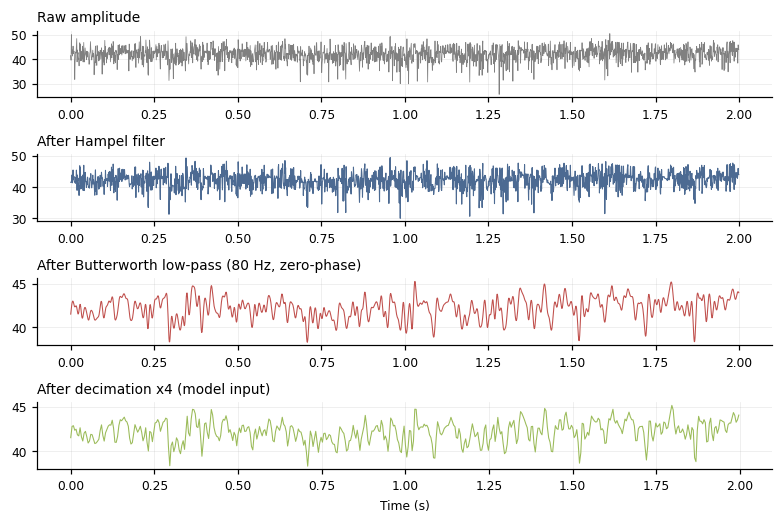

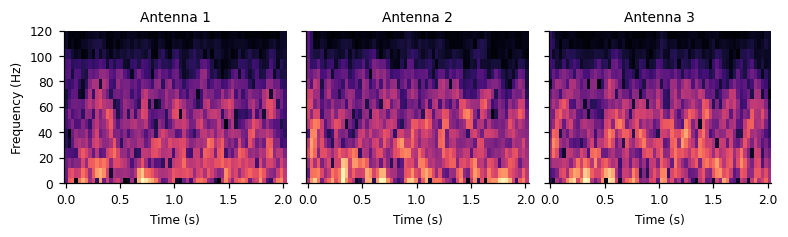

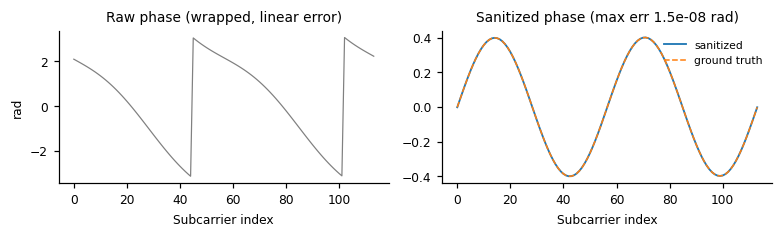

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from src.preprocessing import (PreprocessConfig, to_tensor_layout, hampel_filter, butter_lowpass,
                               preprocess_amplitude, doppler_spectrogram, sanitize_phase)
from src.data import load_mat, list_split, synthetic_gait_raw
from src.evaluation import plot_preprocessing
FIG = f"{REPO_DIR}/results/figures"; os.makedirs(FIG, exist_ok=True)
CFG = PreprocessConfig()

if DATA_ROOT:
    path, cls = list_split(DATA_ROOT, "train_amp")[0]
    raw = load_mat(path); print("file:", path, "| shape mentah:", raw.shape, "| subjek:", cls)
else:
    raw = synthetic_gait_raw(n_subjects=1, n_train=1, n_test=1)["rawtrain"][0]

x = to_tensor_layout(raw)
stages = {
    "After Hampel filter": hampel_filter(x),
    f"After Butterworth low-pass ({CFG.cutoff_hz:.0f} Hz, zero-phase)": butter_lowpass(hampel_filter(x), CFG.cutoff_hz, CFG.fs_hz),
    f"After decimation x{CFG.downsample} (model input)": preprocess_amplitude(raw, CFG),
}
plot_preprocessing(x, stages, [CFG.fs_hz, CFG.fs_hz, CFG.fs_hz, CFG.fs_hz / CFG.downsample],
                   path=f"{FIG}/preprocessing-stages.png"); plt.show()

f, t, S = doppler_spectrogram(butter_lowpass(hampel_filter(x), CFG.cutoff_hz, CFG.fs_hz), CFG.fs_hz)
fig, ax = plt.subplots(1, 3, figsize=(7.16, 2.2), sharey=True)
for a in range(3):
    ax[a].pcolormesh(t, f, S[a], shading="auto", cmap="magma"); ax[a].set_title(f"Antenna {a+1}")
    ax[a].set_xlabel("Time (s)"); ax[a].set_ylim(0, 120)
ax[0].set_ylabel("Frequency (Hz)"); fig.tight_layout()
fig.savefig(f"{FIG}/doppler-spectrogram.png"); plt.show()

# Demonstrasi phase sanitization pada CSI kompleks tersimulasi
k = np.arange(114); true = 0.4 * np.sin(k / 9)
measured = np.angle(np.exp(1j * (true - 0.11 * k + 2.1)))       # error STO/SFO (linier) + CFO (offset) + wrapping
clean = sanitize_phase(measured[None, :, None])[0, :, 0]
ref = true - (true[-1] - true[0]) / 113 * k; ref -= ref.mean()
fig, ax = plt.subplots(1, 2, figsize=(7.16, 2.2))
ax[0].plot(k, measured, lw=0.8, color="grey"); ax[0].set(title="Raw phase (wrapped, linear error)", xlabel="Subcarrier index", ylabel="rad")
ax[1].plot(k, clean, lw=1.2, label="sanitized"); ax[1].plot(k, ref, "--", lw=1, label="ground truth")
ax[1].set(title=f"Sanitized phase (max err {np.abs(clean-ref).max():.1e} rad)", xlabel="Subcarrier index"); ax[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(f"{FIG}/phase-sanitization.png"); plt.show()

In [ ]:
from src.data import build_arrays, build_synthetic_arrays
VARIANTS = {"filtered": PreprocessConfig(), "raw": PreprocessConfig(hampel=False, denoise="none")}
CACHE = "/content/cache"; os.makedirs(CACHE, exist_ok=True)
ARRAYS = {}
for name, cfg in VARIANTS.items():
    if DATA_MODE == "synthetic":
        a = build_synthetic_arrays(cfg, n_train=39, n_test=21)
    else:
        a = build_arrays(DATA_ROOT, cfg, cache_path=f"{CACHE}/humanid-{name}.npz")
    a["preprocess"] = cfg.to_dict()
    ARRAYS[name] = a
    print(f"[{name}] train {a['Xtrain'].shape} | test {a['Xtest'].shape} | subjek: {[str(c) for c in a['classes']]}")
CLASSES = ARRAYS["filtered"]["classes"]
print("Distribusi sampel latih per subjek:", np.bincount(ARRAYS["filtered"]["ytrain"]))

  train_amp: 100/294
  train_amp: 200/294
  test_amp: 100/546
  test_amp: 200/546
  test_amp: 300/546
  test_amp: 400/546
  test_amp: 500/546
[filtered] train (294, 3, 114, 500) | test (546, 3, 114, 500) | subjek: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '012', '013', '015']
  train_amp: 100/294
  train_amp: 200/294
  test_amp: 100/546
  test_amp: 200/546
  test_amp: 300/546
  test_amp: 400/546
  test_amp: 500/546
[raw] train (294, 3, 114, 500) | test (546, 3, 114, 500) | subjek: ['001', '002', '003', '004', '005', '006', '007', '008', '009', '010', '011', '012', '013', '015']
Distribusi sampel latih per subjek: [21 21 21 21 21 21 21 21 21 21 21 21 21 21]


## 5. Konfigurasi eksperimen
| ID | Model | Loss | Preprocessing | Tujuan |
|---|---|---|---|---|
| E1 | CNN1D | CE | filtered | **Baseline** |
| E2 | CNN-BiLSTM-Attn | CE | filtered | Kontribusi arsitektur |
| E3 | CNN-BiLSTM-Attn | CE + Triplet | filtered | **Model usulan** |
| E4 | CNN-BiLSTM (mean pooling) | CE + Triplet | filtered | Ablation attention |
| E5 | CNN-BiLSTM-Attn | CE + Triplet | raw | Ablation filtering |



In [ ]:
SEEDS = [42]              # untuk laporan final disarankan: [42, 7, 2026]
TRAIN_CFG = dict(epochs=60, batch_size=32, lr=1e-3, weight_decay=1e-4, patience=15, num_workers=2)
EXPS = ["E1", "E2", "E3", "E4", "E5"]
if DATA_MODE == "synthetic":
    TRAIN_CFG.update(epochs=15, patience=8)

## 6. Training & evaluasi closed-set (14 subjek)

In [ ]:
from src.experiments import run_closed_set, run_open_set, summarize, EXPERIMENTS
OUT = f"{REPO_DIR}/results"
runs, STORE = run_closed_set(ARRAYS, EXPS, SEEDS, TRAIN_CFG, OUT)
summary = summarize(runs, metrics=["test_acc", "macro_f1", "top3", "ver_auc", "ver_eer", "latency_ms"])
summary.insert(2, "params", runs.groupby("exp", sort=False)["params"].first().values)
summary.to_csv(f"{OUT}/closedset-summary.csv", index=False)
summary


=== E1 | CNN1D (CE) | seed 42 | params 522,894 ===
ep   1 | train loss 2.5400 acc 0.221 | val loss 2.5816 acc 0.289  *
ep   2 | train loss 2.2543 acc 0.518 | val loss 2.3522 acc 0.533  *
ep   3 | train loss 1.9735 acc 0.655 | val loss 1.8445 acc 0.600  *
ep   4 | train loss 1.6494 acc 0.735 | val loss 1.3615 acc 0.867  *
ep   5 | train loss 1.3558 acc 0.751 | val loss 1.0521 acc 0.889  *
ep   6 | train loss 1.0772 acc 0.900 | val loss 0.9649 acc 0.911  *
ep   7 | train loss 0.8911 acc 0.920 | val loss 0.7461 acc 0.978  *
ep  10 | train loss 0.8004 acc 0.932 | val loss 0.7960 acc 0.911
ep  15 | train loss 0.6861 acc 0.968 | val loss 0.9025 acc 0.933
ep  16 | train loss 0.7032 acc 0.960 | val loss 0.7185 acc 0.978  *
ep  18 | train loss 0.6562 acc 0.984 | val loss 0.6812 acc 1.000  *
ep  19 | train loss 0.6703 acc 0.980 | val loss 0.6385 acc 1.000  *
ep  20 | train loss 0.6677 acc 0.992 | val loss 0.8447 acc 0.911
ep  22 | train loss 0.6622 acc 0.988 | val loss 0.6323 acc 1.000  *
ep  2

,exp,model,params,test_acc,macro_f1,top3,ver_auc,ver_eer,latency_ms
0,E1,CNN1D (CE),522894,0.9963,0.9963,1.0000,0.9995,0.0066,0.7452
1,E2,CNN-BiLSTM-Attn (CE),883438,0.9780,0.9779,0.9963,0.9929,0.0167,3.5278
2,E3,CNN-BiLSTM-Attn (CE+Triplet),883438,0.9744,0.9741,0.9963,0.9960,0.0236,3.2814
3,E4,w/o attention (CE+Triplet),850414,0.9579,0.9576,0.9963,0.9964,0.0183,3.4825
4,E5,w/o filtering (CE+Triplet),883438,0.9817,0.9817,0.9945,0.9955,0.0137,3.4469


### 6.1 Kurva training — baseline vs model usulan

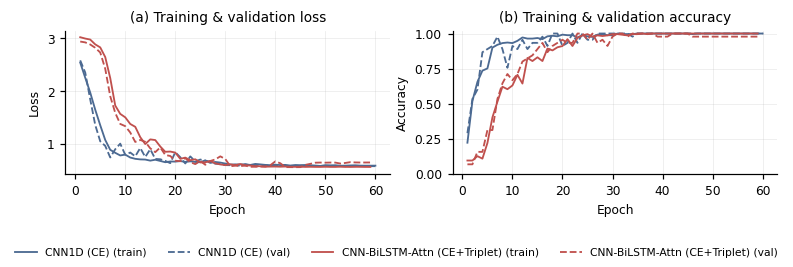

In [ ]:
from src.evaluation import plot_history, plot_confusion, plot_roc, plot_tsne
s0 = SEEDS[0]
plot_history({EXPERIMENTS[e]["label"]: STORE[(e, s0)]["hist"] for e in ["E1", "E3"]},
             f"{FIG}/training-curves.png"); plt.show()

### 6.2 Confusion matrix (dinormalisasi per baris = recall per subjek)

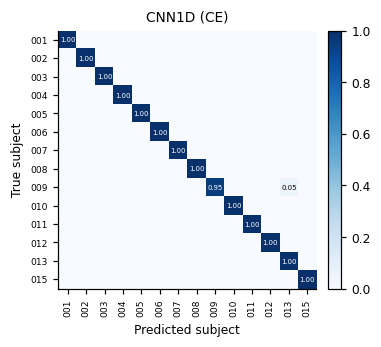

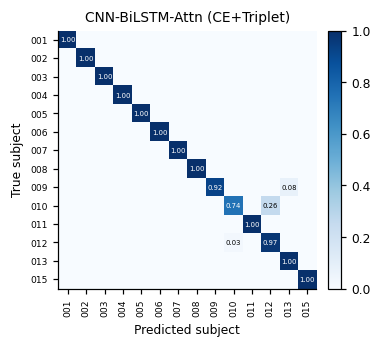

Pasangan tertukar terbanyak (jumlah, true -> pred): [(np.int64(10), np.str_('010'), np.str_('012')), (np.int64(3), np.str_('009'), np.str_('013')), (np.int64(1), np.str_('012'), np.str_('010'))]


In [ ]:
for e in ["E1", "E3"]:
    o = STORE[(e, s0)]["out"]
    plot_confusion(o["y"], o["pred"], CLASSES, EXPERIMENTS[e]["label"], f"{FIG}/confusion-{e}.png"); plt.show()

# subjek yang paling sering tertukar pada model usulan -> bahan analisis kritis di laporan
from sklearn.metrics import confusion_matrix
o = STORE[("E3", s0)]["out"]; cm = confusion_matrix(o["y"], o["pred"]); np.fill_diagonal(cm, 0)
pairs = sorted(((cm[i, j], CLASSES[i], CLASSES[j]) for i in range(len(cm)) for j in range(len(cm)) if cm[i, j]), reverse=True)[:5]
print("Pasangan tertukar terbanyak (jumlah, true -> pred):", pairs)

### 6.3 Verifikasi biometrik (ROC & EER) dan ruang embedding (t-SNE)

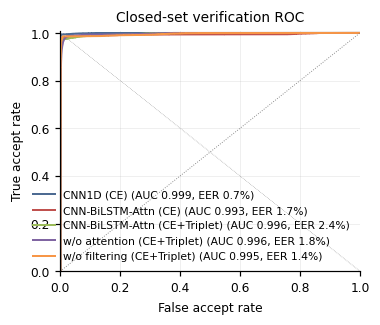

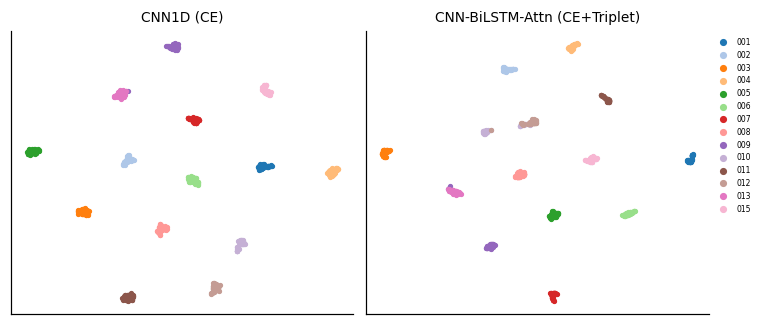

In [ ]:
plot_roc({EXPERIMENTS[e]["label"]: STORE[(e, s0)]["ver"] for e in EXPS},
         f"{FIG}/roc-closedset.png", "Closed-set verification ROC"); plt.show()
plot_tsne({EXPERIMENTS[e]["label"]: STORE[(e, s0)]["out"]["emb"] for e in ["E1", "E3"]},
          STORE[("E3", s0)]["out"]["y"], CLASSES, f"{FIG}/tsne-embeddings.png"); plt.show()

### 6.4 Interpretabilitas: bobot temporal attention


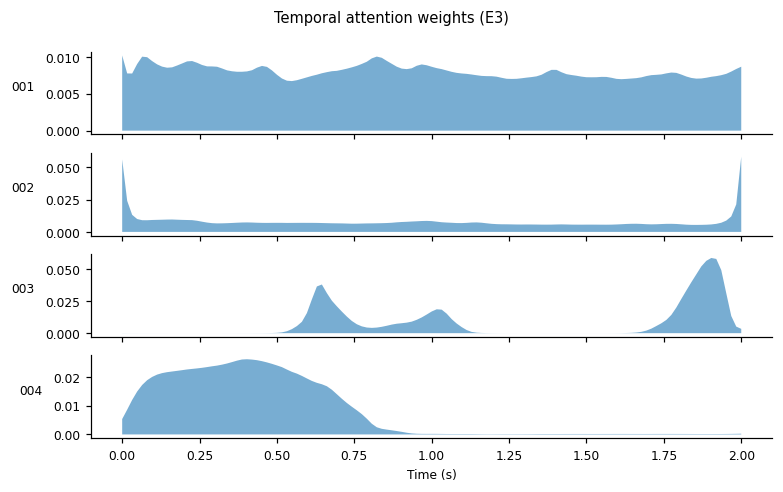

In [ ]:
import torch
m = STORE[("E3", s0)]["model"].eval(); mean, std = STORE[("E3", s0)]["norm"]
Xte, yte = ARRAYS["filtered"]["Xtest"], ARRAYS["filtered"]["ytest"]
idx = [np.where(yte == c)[0][0] for c in np.unique(yte)[:4]]
fig, ax = plt.subplots(len(idx), 1, figsize=(7.16, 1.1 * len(idx)), sharex=True)
dev = next(m.parameters()).device
for a, i in zip(ax, idx):
    with torch.no_grad():
        m(torch.from_numpy(((Xte[i] - mean) / std)[None]).float().to(dev))
    w = m.last_attn[0].cpu().numpy()
    tt = np.linspace(0, Xte.shape[-1] / (CFG.fs_hz / CFG.downsample), len(w))
    a.fill_between(tt, w, alpha=0.6); a.set_ylabel(str(CLASSES[yte[i]]), rotation=0, labelpad=15)
ax[-1].set_xlabel("Time (s)"); fig.suptitle("Temporal attention weights (E3)", y=1.0)
fig.tight_layout(); fig.savefig(f"{FIG}/attention-weights.png"); plt.show()

## 7. Evaluasi open-set



=== O1 open-set | CNN-BiLSTM-Attn (CE) | seed 42 | unseen ['001', '007', '009', '010'] ===
ep   1 | train loss 2.3016 acc 0.101 | val loss 2.3035 acc 0.094  *
ep   2 | train loss 2.2922 acc 0.101 | val loss 2.2976 acc 0.094  *
ep   3 | train loss 2.2686 acc 0.112 | val loss 2.2586 acc 0.094  *
ep   4 | train loss 2.1893 acc 0.382 | val loss 2.0497 acc 0.500  *
ep   5 | train loss 1.9070 acc 0.539 | val loss 1.5508 acc 0.500  *
ep   6 | train loss 1.4450 acc 0.517 | val loss 1.1562 acc 0.688  *
ep   7 | train loss 1.1276 acc 0.640 | val loss 1.0268 acc 0.688  *
ep   8 | train loss 1.0388 acc 0.725 | val loss 0.9283 acc 0.875  *
ep   9 | train loss 0.8694 acc 0.854 | val loss 0.7348 acc 1.000  *
ep  10 | train loss 0.8513 acc 0.848 | val loss 0.6803 acc 0.969
ep  11 | train loss 0.6802 acc 0.955 | val loss 0.5977 acc 1.000  *
ep  15 | train loss 0.6117 acc 0.961 | val loss 0.5546 acc 1.000  *
ep  16 | train loss 0.5657 acc 0.989 | val loss 0.5305 acc 1.000  *
ep  18 | train loss 0.5281 

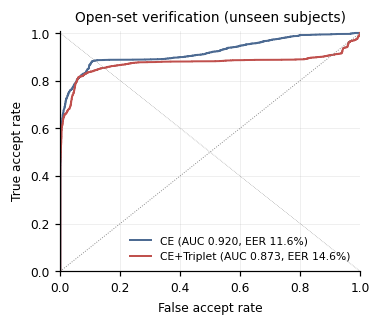

,exp,model,unseen_auc,unseen_eer,1shot_acc,5shot_acc
0,O1,CNN-BiLSTM-Attn (CE),0.9203,0.1161,0.8744,0.9729
1,O2,CNN-BiLSTM-Attn (CE+Triplet),0.8728,0.1465,0.8204,0.8660


In [ ]:
OPEN, OSTORE = run_open_set(ARRAYS["filtered"], n_unseen=4, seeds=SEEDS, train_cfg=TRAIN_CFG, outdir=OUT)
osum = summarize(OPEN, metrics=["unseen_auc", "unseen_eer", "1shot_acc", "5shot_acc"])
osum.to_csv(f"{OUT}/openset-summary.csv", index=False)
plot_roc({"CE": OSTORE[("O1", s0)]["ver"], "CE+Triplet": OSTORE[("O2", s0)]["ver"]},
         f"{FIG}/roc-openset.png", "Open-set verification (unseen subjects)"); plt.show()
osum

## 8. Ekspor hasil

In [ ]:
from src.reporting import export_latex
REPORT = f"{REPO_DIR}/report"
export_latex(runs, OPEN, STORE, ARRAYS["filtered"], REPORT, FIG, SEEDS, [str(c) for c in CLASSES])
print(open(f"{REPORT}/results.tex").read()[:3000])

% File ini dibuat otomatis oleh src/reporting.py -- jangan diedit manual.
\newcommand{\NSub}{14}
\newcommand{\NTrain}{294}
\newcommand{\NTest}{546}
\newcommand{\NSeeds}{1}
\newcommand{\SeedList}{42}
\newcommand{\SeedNote}{satu seed (42)}
\newcommand{\AccEone}{99.63}
\newcommand{\FoneEone}{99.63}
\newcommand{\EerEone}{0.66}
\newcommand{\AucEone}{0.9995}
\newcommand{\LatEone}{0.7}
\newcommand{\ParamsEone}{523k}
\newcommand{\AccEtwo}{97.80}
\newcommand{\FoneEtwo}{97.79}
\newcommand{\EerEtwo}{1.67}
\newcommand{\AucEtwo}{0.9929}
\newcommand{\LatEtwo}{3.5}
\newcommand{\ParamsEtwo}{883k}
\newcommand{\AccEthree}{97.44}
\newcommand{\FoneEthree}{97.41}
\newcommand{\EerEthree}{2.36}
\newcommand{\AucEthree}{0.9960}
\newcommand{\LatEthree}{3.3}
\newcommand{\ParamsEthree}{883k}
\newcommand{\AccEfour}{95.79}
\newcommand{\FoneEfour}{95.76}
\newcommand{\EerEfour}{1.83}
\newcommand{\AucEfour}{0.9964}
\newcommand{\LatEfour}{3.5}
\newcommand{\ParamsEfour}{850k}
\newcommand{\AccEfive}{98.17}
\newcommand{\F

## 10. Simpan hasil


In [ ]:
import shutil
!ls -R {OUT} | head -40
archive = shutil.make_archive("/content/GaitCSI-results", "zip", REPO_DIR)
report_zip = shutil.make_archive("/content/GaitCSI-Report-Overleaf", "zip", f"{REPO_DIR}/report")
if os.path.isdir("/content/drive/MyDrive"):
    for z in (archive, report_zip):
        shutil.copy(z, "/content/drive/MyDrive/"); print("Tersalin ke My Drive:", os.path.basename(z))
from google.colab import files
files.download(archive)
files.download(report_zip)

/content/GaitCSI-ID/results:
checkpoints
closedset-runs.csv
closedset-summary.csv
figures
openset-runs.csv
openset-summary.csv

/content/GaitCSI-ID/results/checkpoints:
E1-seed42.pt
E2-seed42.pt
E3-seed42.pt
E4-seed42.pt
E5-seed42.pt

/content/GaitCSI-ID/results/figures:
attention-weights.png
confusion-E1.png
confusion-E3.png
doppler-spectrogram.png
phase-sanitization.png
preprocessing-stages.png
roc-closedset.png
roc-openset.png
training-curves.png
tsne-embeddings.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>